# 보배드림 리뷰·커뮤니티 데이터 분석

보배드림 국산차·수입차 게시판에서 모은 구매 고민 글과 댓글로 **사람들이 차를 살 때 무엇을 중점으로 보는지**를 본다.

| 절 | 내용 |
|---|---|
| 1 | 데이터셋 개요: 무엇을 얼마나 모았나, `info()`, 빈 값·중복·길이 분포 |
| 2 | 구매 고민 글 추리기 |
| 3~5 | 조건 사전, 글쓴이가 본문에 적는 조건, 댓글이 근거로 드는 조건 |
| 6 | 자주 나오는 단어 |
| 7 | 감정 분류: 댓글 문장을 긍정·부정으로 나누기 |
| 8 | 긍정 문장과 부정 문장에 많이 나오는 키워드 |
| 9 | 차를 살 때 무엇을 중점으로 보나: 항목별 언급량과 긍정·부정 |
| 10 | 에이전트가 물어야 할 것: 질문 후보, 되묻기 |
| 11~12 | 정리, 한계 |

- 데이터: `data/processed/bobaedream/2026-11-26.jsonl` (`scripts/crawl_bobaedream.py`로 수집)
- 2~6절과 10절은 이전 분석을 새 데이터로 다시 실행한 것이고, 1절과 7~9절을 새로 넣었다.

> **일부 데이터로 실행한 결과다.** 수집이 중간에 멈춰 글 3,105/3,818건만 들어 있다. 국산차 게시판 글만 있고 수입차 게시판 글은 없다.
> 목록 앞쪽부터 받은 것이라 무작위 표본이 아니다. 수집이 끝난 뒤 다시 실행하면 수치가 달라진다.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 180)
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b"

DAY = "2026-11-26"

with open(f"data/processed/bobaedream/{DAY}.jsonl", encoding="utf-8") as f:
    posts_all = pd.DataFrame([json.loads(line) for line in f])
posts_all["posted_at"] = pd.to_datetime(posts_all["posted_at"])
print(f"수집한 글 {len(posts_all):,}건")

수집한 글 3,105건


## 1. 데이터셋 개요

### 1.1 무엇을 모았나

`docs/project.md`는 리뷰·커뮤니티 출처로 다섯 가지를 적어 두었고, 지금까지 수집한 것은 보배드림 하나다.

| 출처 | 상태 | 내용 |
|---|---|---|
| 보배드림 | 수집함 (이 Notebook) | 국산차·수입차 게시판에서 제목 검색어 11개로 찾은 글과 댓글. 2024년 이후 글 |
| 유튜브 차량 리뷰 | 아직 수집하지 않음 | - |
| 클리앙 | 아직 수집하지 않음 | - |
| 헤이딜러 후기 | 아직 수집하지 않음 | - |
| 자동차 매체 시승기 | 아직 수집하지 않음 | - |

보배드림은 게시판마다 검색어별로 목록을 100쪽까지 훑어 글 주소를 모은 뒤 글과 댓글을 받는다.
검색어는 고민, 추천, 첫차, 중고차, 구매, 구입, 살까, 조언, 골라, 어떤차, 뭐살이다.

In [2]:
BOARD = {"national": "국산차 게시판", "import": "수입차 게시판"}
KEYWORDS = ["고민", "추천", "첫차", "중고차", "구매", "구입", "살까", "조언", "골라", "어떤차", "뭐살"]

n_comments = posts_all["comments"].str.len()
by_board = pd.DataFrame({
    "글": posts_all.groupby("board").size(),
    "댓글": n_comments.groupby(posts_all["board"]).sum(),
    "가장 이른 글": posts_all.groupby("board")["posted_at"].min().dt.date,
    "가장 늦은 글": posts_all.groupby("board")["posted_at"].max().dt.date,
}).reindex(BOARD).rename(index=BOARD)
by_board[["글", "댓글"]] = by_board[["글", "댓글"]].fillna(0).astype(int)
print(by_board.astype(object).fillna("-").to_string())
print()

squashed = posts_all["title"].str.replace(" ", "")
by_keyword = pd.Series({k: squashed.str.contains(k).sum() for k in KEYWORDS}, name="제목에 검색어가 있는 글")
print(by_keyword.to_frame().T.to_string())
print(f"검색어가 제목에 하나도 없는 글 {(~squashed.str.contains('|'.join(KEYWORDS))).sum():,}건 (띄어쓰기를 무시하고 셈)")

            글     댓글     가장 이른 글     가장 늦은 글
board                                       
국산차 게시판  3105  24407  2023-01-03  2026-11-26
수입차 게시판     0      0           -           -

                고민   추천   첫차   중고차   구매   구입  살까   조언  골라  어떤차  뭐살
제목에 검색어가 있는 글  458  675  189  1328  675  196  14  237   6    9   2
검색어가 제목에 하나도 없는 글 17건 (띄어쓰기를 무시하고 셈)


### 1.2 글 표

글 하나가 한 줄이다.

| 컬럼 | 뜻 |
|---|---|
| id, url | 글 번호와 주소 |
| board | 게시판 (`national` 국산차, `import` 수입차) |
| title, body | 제목과 본문 |
| posted_at | 작성 시각 |
| views, recommends | 조회 수, 추천 수 |
| comment_count | 목록 화면에 적힌 댓글 수 |
| comments | 수집한 댓글 목록 (list) |

In [3]:
posts_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3105 entries, 0 to 3104
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   source         3105 non-null   str           
 1   id             3105 non-null   str           
 2   url            3105 non-null   str           
 3   board          3105 non-null   str           
 4   title          3105 non-null   str           
 5   posted_at      3105 non-null   datetime64[us]
 6   views          3105 non-null   int64         
 7   recommends     3105 non-null   int64         
 8   comment_count  3103 non-null   float64       
 9   body           3050 non-null   str           
 10  comments       3105 non-null   object        
 11  crawled_date   3105 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(2), object(1), str(7)
memory usage: 291.2+ KB


In [4]:
posts_all[["views", "recommends", "comment_count"]].describe().T.style.format("{:,.1f}")

,count,mean,std,min,25%,50%,75%,max
views,"3,105.0","1,124.7","1,764.0",50.0,455.0,695.0,"1,183.0","36,560.0"
recommends,"3,105.0",4.2,15.4,0.0,0.0,0.0,1.0,230.0
comment_count,"3,103.0",8.1,7.8,0.0,4.0,6.0,11.0,178.0


### 1.3 댓글 표

`comments`를 풀어 댓글 하나가 한 줄인 표로 만든다.

| 컬럼 | 뜻 |
|---|---|
| post_id | 댓글이 달린 글 |
| id, date | 댓글 번호와 작성 시각 |
| is_op | 글쓴이가 단 댓글인가 |
| is_reply | 다른 댓글에 단 답글인가 |
| text | 내용 |
| up, down | 댓글 추천·반대 수 |

In [5]:
comments_all = pd.DataFrame([{"post_id": p.id, **c} for p in posts_all.itertuples() for c in p.comments])
comments_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 24407 entries, 0 to 24406
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   post_id   24407 non-null  str  
 1   id        24407 non-null  str  
 2   date      24407 non-null  str  
 3   is_op     24407 non-null  bool 
 4   is_reply  24407 non-null  bool 
 5   text      24407 non-null  str  
 6   up        24407 non-null  int64
 7   down      24407 non-null  int64
dtypes: bool(2), int64(2), str(4)
memory usage: 1.2 MB


In [6]:
print(f"글쓴이 댓글 {comments_all['is_op'].mean():.1%}, 답글 {comments_all['is_reply'].mean():.1%}")
comments_all[["up", "down"]].describe().T.style.format("{:,.2f}")

글쓴이 댓글 25.8%, 답글 31.6%


,count,mean,std,min,25%,50%,75%,max
up,"24,407.00",0.45,1.38,0.00,0.00,0.00,1.00,49.00
down,"24,407.00",0.21,0.81,0.00,0.00,0.00,0.00,45.00


### 1.4 빈 값·중복·어긋나는 값

In [7]:
body_length = posts_all["body"].fillna("").str.len()
comment_length = comments_all["text"].fillna("").str.len()
checks = pd.Series({
    "본문이 없는 글 (null)": posts_all["body"].isna().sum(),
    "본문이 20자 미만인 글": ((body_length < 20) & posts_all["body"].notna()).sum(),
    "댓글이 없는 글": (n_comments == 0).sum(),
    "목록의 댓글 수가 없는 글 (null)": posts_all["comment_count"].isna().sum(),
    "목록의 댓글 수와 수집한 댓글 수가 다른 글": ((posts_all["comment_count"] != n_comments) & posts_all["comment_count"].notna()).sum(),
    "글 번호가 중복된 글": posts_all["id"].duplicated().sum(),
    "제목이 다른 글과 같은 글": posts_all["title"].duplicated().sum(),
    "2024년 이전에 쓴 글": (posts_all["posted_at"] < "2024-01-01").sum(),
    "내용이 빈 댓글": (comment_length == 0).sum(),
    "5자 미만인 댓글": (comment_length < 5).sum(),
}, name="건수")
checks.to_frame().style.format("{:,}")

,건수
본문이 없는 글 (null),55
본문이 20자 미만인 글,146
댓글이 없는 글,89
목록의 댓글 수가 없는 글 (null),2
목록의 댓글 수와 수집한 댓글 수가 다른 글,353
글 번호가 중복된 글,0
제목이 다른 글과 같은 글,25
2024년 이전에 쓴 글,7
내용이 빈 댓글,0
5자 미만인 댓글,"1,502"


In [8]:
gap = posts_all["comment_count"] - n_comments
print("[목록의 댓글 수 - 수집한 댓글 수] 차이가 있는 글")
print(gap[gap.notna() & (gap != 0)].astype(int).value_counts().sort_index().rename("글 수").to_frame().T.to_string())
print()
print("[차이가 5개를 넘는 글]")
print(posts_all.assign(수집한_댓글=n_comments, 차이=gap)[gap > 5][["title", "comment_count", "수집한_댓글", "차이"]].to_string(index=False))
print()
print("[본문이 없는 글의 제목]")
print(posts_all.loc[posts_all["body"].isna(), "title"].head(8).to_string(index=False))
print()
print("[같은 제목이 여러 번 나오는 글]")
print(posts_all["title"][posts_all["title"].duplicated(keep=False)].value_counts().head(8).to_string())

[목록의 댓글 수 - 수집한 댓글 수] 차이가 있는 글
     1    2    3    5    100  102
글 수  299   45    6    1    1    1

[차이가 5개를 넘는 글]
                   title  comment_count  수집한_댓글    차이
형님들 차 등록해야하는데 존나 고민됩니다..          135.0      35 100.0
             아버지 차 선물 추천          178.0      76 102.0

[본문이 없는 글의 제목]
이차 어떤가요?당근에서 살까 하는데요
     신차 구입 트랙스 크로스오버
      29세 첫 차 추천좀...
           40대 맘의 고민
             추천 받읍미다
    전주중고차님이신가?만키로 ㄷㄷ
              추천바랍니다
              추천바랍니다

[같은 제목이 여러 번 나오는 글]
title
재업) 차 구매 팁                       2
중고차 살때 어떤 차를 사야 할지 모르겠다? 그럴땐!    2
팰리세이드 도어커튼 추천부탁드립니다              2
추천바랍니다                           2
고민중                              2
전남 목포 ㅁㄷㅅ 중고차 조심들하시길             2
중고차 문의                           2
큰 고민중                            2


### 1.5 길이와 반응의 분포

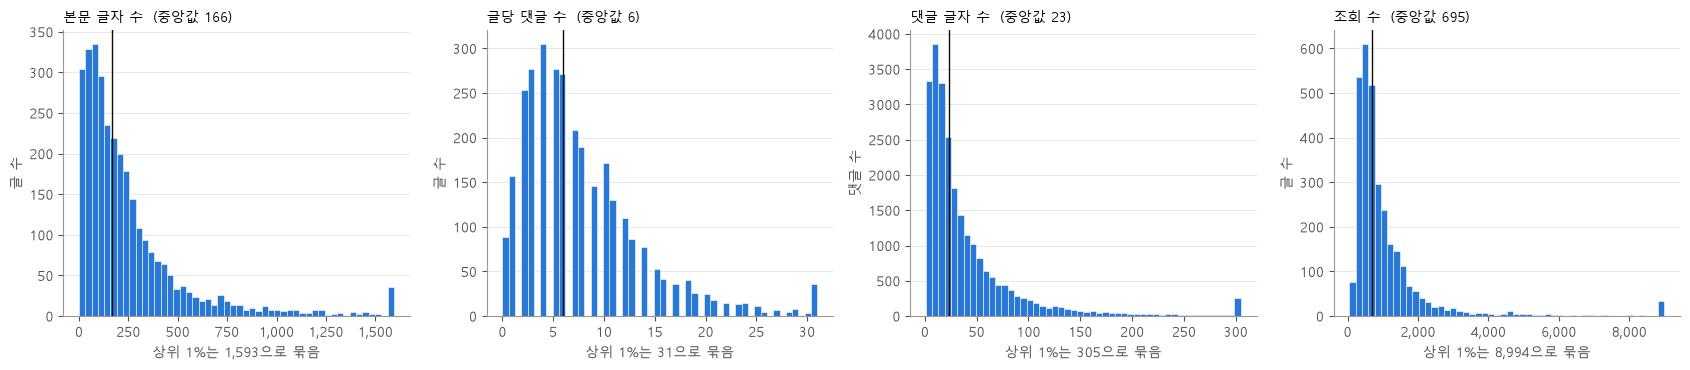

,count,mean,std,min,25%,50%,75%,99%,max
본문 글자 수,"3,105",264,367,0,77,166,313,"1,593","8,621"
글당 댓글 수,"3,105",8,7,0,4,6,10,31,77
댓글 글자 수,"24,407",42,63,1,12,23,49,305,"1,287"
조회 수,"3,105","1,125","1,764",50,455,695,"1,183","8,994","36,560"


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
panels = [(body_length, "본문 글자 수", "글"), (n_comments, "글당 댓글 수", "글"),
          (comment_length, "댓글 글자 수", "댓글"), (posts_all["views"], "조회 수", "글")]
for ax, (values, label, unit) in zip(axes, panels):
    top = values.quantile(0.99)
    ax.hist(values.clip(upper=top), bins=50, color=BLUE, edgecolor="white", linewidth=0.4)
    ax.axvline(values.median(), color=INK, linewidth=1)
    ax.set_title(f"{label}  (중앙값 {values.median():,.0f})", loc="left", fontsize=10)
    ax.set_xlabel(f"상위 1%는 {top:,.0f}으로 묶음")
    ax.set_ylabel(f"{unit} 수")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

pd.DataFrame({label: values.describe(percentiles=[0.25, 0.5, 0.75, 0.99]) for values, label, unit in panels}).T.style.format("{:,.0f}")

In [10]:
print("[본문이 가장 긴 글]")
print(posts_all.assign(글자수=body_length).nlargest(5, "글자수")[["title", "글자수", "comment_count"]].to_string(index=False))
print()
print("[조회 수가 가장 많은 글]")
print(posts_all.nlargest(5, "views")[["title", "views", "comment_count"]].to_string(index=False))

[본문이 가장 긴 글]
                                                title  글자수  comment_count
   크몽에서 카탈로그 제작 맡겼다가 분쟁 중입니다… 전공 정보 문제까지 있어 조언 부탁드립니다 8621           26.0
                                  5월 중고차 시세는 다음과 같습니다 4410            0.0
                         우리집 모터홈 Pilote V630J 홍당무 구입기 3946           32.0
                           현대인증중고차 이용 후기(피해사례 공유)입니다. 3301            0.0
[조언 부탁] 기아 오토큐의 정비지연, 오진비용전가와 본사 주재원의 무책임한 대처를 고발합니다. 3278            2.0

[조회 수가 가장 많은 글]
                   title  views  comment_count
형님들 차 등록해야하는데 존나 고민됩니다..  36560          135.0
         남자친구 만든 유부녀의 고민  24846           22.0
 현대자동차ㅡ차 구입하고 너무 분통터집니다.  24594           48.0
             아버지 차 선물 추천  22312          178.0
            캐스퍼 구입 했습니다~  20278           71.0


- **본문이 없는 글**: 본문 글자가 없는 글이다(사진만 올린 글로 보인다). 지우지 않고 제목만으로 분석에 넣는다.
- **댓글 수가 어긋나는 글**: 수집한 댓글이 목록의 댓글 수보다 적은 글이 있다. 대부분 1~3개 차이다.
  댓글이 100개를 넘는 글 2건은 100개 넘게 덜 받았다. 수집 Script가 글 화면에 처음 보이는 댓글 한 쪽만 읽기 때문이다.
- **제목이 같은 글**: 같은 글을 다시 올렸거나("재업") "추천바랍니다"처럼 흔한 제목이다. 글 번호가 다르므로 그대로 둔다.
- **길이**: 본문과 댓글 길이는 오른쪽 꼬리가 길다. 가장 긴 글들은 구매 고민이 아니라 분쟁·피해 사례나 정보 글이다.
- **조회 수**: 조회 수가 가장 많은 글에는 차와 관계없는 글도 있다. 검색어("고민", "추천")에 걸린 글이 모두 차 이야기는 아니어서, 2절에서 구매 고민 글만 추린다.
- 댓글은 대부분 한두 문장으로 짧다. 그래서 감정 분류는 문장 단위로 한다(7절).

### 1.6 분석에 쓸 글

목록 날짜에 연도가 없어 연도를 거꾸로 계산하다 어긋난 2024년 이전 글은 뺀다. 본문이 없는 글은 빈 문자열로 둔다.

In [11]:
posts = posts_all[posts_all["posted_at"] >= "2024-01-01"].reset_index(drop=True)
posts["body"] = posts["body"].fillna("")
print(f"분석에 쓸 글 {len(posts):,}건 (2024년 이후)")

분석에 쓸 글 3,098건 (2024년 이후)


분석에 쓸 글의 게시판별 건수와 월별 글 수다.

board
national    3098
댓글 24,340개, 글당 중앙값 6개, 댓글 없는 글 89건


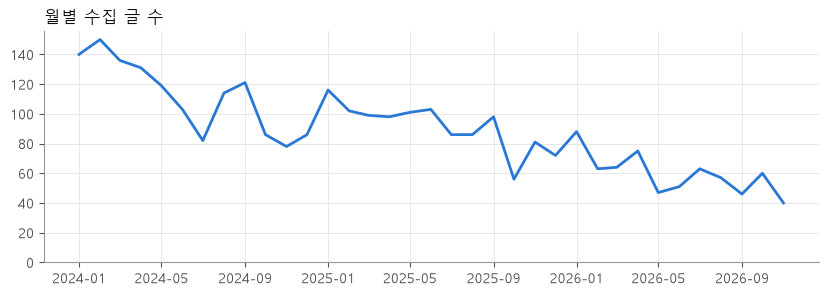

In [12]:
n_comments = posts["comments"].str.len()
print(posts["board"].value_counts().to_string())
print(f"댓글 {n_comments.sum():,}개, 글당 중앙값 {n_comments.median():.0f}개, 댓글 없는 글 {(n_comments == 0).sum()}건")

monthly = posts.set_index("posted_at").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.set_title("월별 수집 글 수", loc="left")
ax.set_ylim(0)
plt.show()

## 2. 구매 고민 글 추리기

검색어("추천", "고민")에 걸린 글에는 "타이어 추천", "맛집 추천", "중고차 팔 때" 같은 글도 섞여 있다.
제목 규칙으로 **차를 고르는 중인 글**만 남긴다.

- 구매 의도: 제목에 추천·고민·조언·살까·구매·vs·첫차 등
- 차 맥락: 제목이나 본문 앞부분에 차종·예산·연료 등
- 제외: 용품·정비 관련(타이어, 썬팅, 블박 …), 구매 이후·판매 관련(출고, 환불, 팔려고 …)

규칙 기반이라 오분류가 있다. 아래 표본으로 정확도를 눈으로 확인한다.

In [13]:
INTENT = r"추천|고민|조언|살까|사려|살려|사고\s?싶|구매|구입|첫\s?차|입문|vs|골라|선택|어떤\s?차|어느\s?차|뭐\s?살|뭘\s?살|대차|교체|바꾸려|넘어가|어떨까|괜찮을까|어떤가요"
CAR = (r"차|suv|세단|경차|하이브리드|전기|디젤|가솔린|lpg|4륜|사륜|트럭|그랜[저져]|쏘나타|아반떼|\bk\d\b|카니발|쏘렌토|싼타페|"
       r"팰리세이드|투싼|스포티지|\bg\d0\b|\bgv\d0\b|bmw|벤츠|아우디|테슬라|제네시스|모델\s?[3ysx]|볼보|렉서스|토요타|혼다|"
       r"폭스바겐|미니|포르쉐|레이|모닝|캐스퍼|셀토스|코나|트레일블레이저|토레스|ev\d|아이오닉|만원|천만|예산")
OFF = (r"타이어|썬팅|틴팅|블랙박스|블박|네비|세차|코팅|광택|오일|정비|공업사|카센터|와이퍼|배터리|밧데리|하이패스|노래|영화|음악|"
       r"맛집|국밥|유산균|게임|mmorpg|주식|석유주|신발|런닝화|칼|가위|노트북|휴대폰|핸드폰|모니터|시계|여행|카메라|매트|시트커버|"
       r"방향제|용품|도색|도장|덴트|휠|스피커|앰프|충전기\s?설치|운전\s?연수|수동\s?운전|배우자|드라이브")
AFTER = (r"판매|팔[려았고까때]|매도|매입|환불|소송|계약서|사기|후기|샀습니다|샀어요|출고|인수|구매했|구입했|레몬법|고장|수리|"
         r"보험이력|사고이력|성능점검|이전비|취등록|등록지|흠집|기스|떨림|부식|딜러한테|주의\s?점|사는\s?법|정보\]|순위|엠블럼")

title = posts["title"].str.lower()
head = (posts["title"] + " " + posts["body"].str[:400]).str.lower()
posts["is_purchase"] = (title.str.contains(INTENT) & head.str.contains(CAR)
                        & ~title.str.contains(OFF) & ~title.str.contains(AFTER))
buy = posts[posts["is_purchase"]].reset_index(drop=True)
print(f"구매 고민 글 {len(buy):,}건 / 전체 {len(posts):,}건")

구매 고민 글 1,626건 / 전체 3,098건


In [14]:
print("[남긴 글 표본]")
print(buy["title"].sample(20, random_state=0).to_string(index=False))
print()
print("[뺀 글 표본]")
print(posts.loc[~posts["is_purchase"], "title"].sample(20, random_state=0).to_string(index=False))

[남긴 글 표본]
                      장모님 중고차 추천 부탁드립니다!
                           전시차 구매 괜찮은가요?
           형님들 앞휀다 교체 케이카 중고차량 사도 괜찮을까요?
                    3초 차 구매 조언 좀 부탁드립니다.
                    중고차 선택장애. 조언 부탁드립니다.
      아반떼 하향들 구매하려는데요.. 혹시 제품명을 알수 있을까요?
              29살 예비 아빠 새 차 구매 조언 부탁드립니다
중고차추천부탁 (2015년식 LF 소나타. 2000식.더뉴 K5 2세대)
                       GV80 중고 구매 질믄 드려요
                       중고차 살 때 옵션 vs 킬로수
                     4인승 SUV 추천 부탁 드립니다.
                            30대 여성 첫차 추천
         아반떼 ad 첫차 중고로 구매 괜찮은지 한번만 봐주세요ㅜ
                        21살 첫 차 추천 부탁드려요
                           3인 패밀리카 차량 고민
                     카티더안심, 공임나라 고민입니다..
                      차량 구매여부 조언 부탁드립니다!
                     중고차 구매 조언 받고싶습니다~^^
                         첫차 구매 질문드립니다 ㅜㅜ
                     1000만원 중고차 선택 도와주세요

[뺀 글 표본]
                  형님들 215/55R18 타이어 추천해 주십시오.
                          중고차 고장 사기 어떻게 해야할까요
                     어머니 명의 중고차 개인판매할때 필요한 서류
               신차랑 가격차

## 3. 조건 사전

글과 댓글에 나오는 조건을 주제별 정규식으로 잡는다. 같은 문장이 여러 주제에 걸릴 수 있다.
`agent-design.md`의 대화 에이전트 질문 항목(예산, 소득·월 여유, 용도, 탑승 인원, 보유 기간)도 이 안에 들어 있다.

In [15]:
TOPICS = {
    "예산": r"예산|\d+\s?만\s?원|\d+만원|\d+천|천만|\d억|가격대|총알|얼마\s?(까지|정도|생각)",
    "소득·재정": r"연봉|월급|소득|수입|실수령|외벌이|맞벌이|자산|모아\s?둔|저축|대출|빚|생활비|고정\s?지출",
    "결제 방식": r"할부|현금|리스|장기\s?렌트|렌트|일시불|금리|선수금|선납|무이자",
    "주행거리": r"주행\s?거리|연간|1년에|일년에|년에\s?\d|월에\s?\d|하루에|\d+\s?(km|키로|킬로)|만\s?키로|왕복|편도|많이\s?타|적게\s?타",
    "주행 환경": r"출퇴근|통근|장거리|단거리|시내|고속도로|국도|시골|산길|눈길|오프로드",
    "용도": r"용도|캠핑|차박|레저|업무용|영업용|출장|세컨|주말|낚시|골프",
    "가족·탑승 인원": r"가족|아이|애기|아기|애가|애\s?둘|와이프|아내|남편|부모님|탑승|\d인승|카시트|유모차|결혼|미혼|신혼|자녀|육아|임신|출산|혼자\s?(타|탈)",
    "주차·차 크기": r"주차|지하\s?주차장|기계식|골목|차폭|전장|크기|사이즈|소형|중형|대형|준중형|준대형",
    "연료·충전": r"충전|완속|급속|전기차|하이브리드|하브|디젤|가솔린|휘발유|lpg|연료",
    "보유 기간": r"보유|오래\s?(탈|타)|몇\s?년\s?(탈|타)|\d+\s?년\s?(이상\s?)?(탈|타)|평생|폐차\s?(까지|할\s?때)|탈\s?생각",
    "신차/중고": r"신차|중고|새\s?차|인증\s?중고|출고",
    "나이·경력": r"\d{2}\s?살|\d0대|나이|사회\s?초년생|초보|운전\s?경력|장롱|면허",
    "현재 차량": r"타던|지금\s?타는|현재\s?타|기존\s?차|타고\s?있|처분|팔고|대차|내\s?차는",
    "선호: 성능·승차감": r"승차감|성능|출력|가속|마력|정숙|소음|하체|핸들링|주행감|펀\s?카",
    "선호: 디자인·브랜드": r"디자인|외관|이쁘|예쁘|멋|브랜드|하차감|수입차|국산차|감성",
    "선호: 연비·유지비": r"연비|유지비|보험료|자동차세|감가|잔존|기름값|유류비",
    "선호: 공간·옵션·안전": r"공간|트렁크|2열|3열|실내|옵션|편의\s?사양|안전|ADAS|크루즈|통풍|열선",
}
TOPIC_RE = {k: re.compile(v, re.I) for k, v in TOPICS.items()}

def topics_in(text):
    return [k for k, r in TOPIC_RE.items() if r.search(text or "")]

## 4. 글쓴이가 본문에서 먼저 밝히는 조건

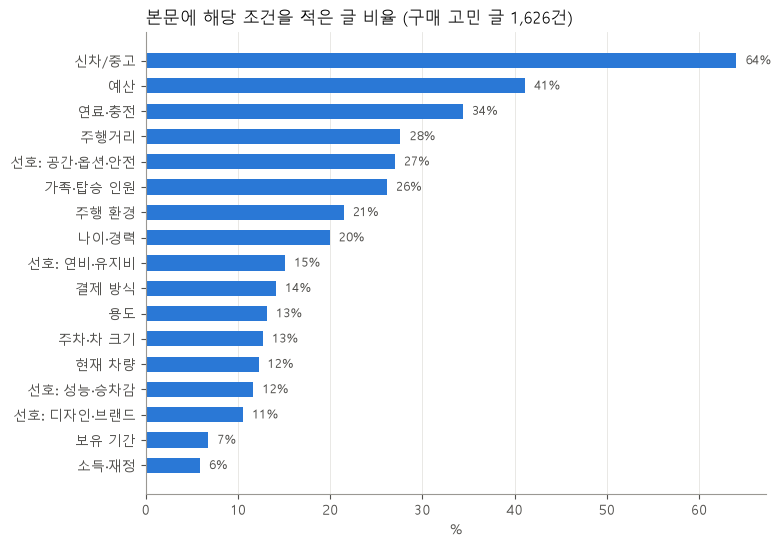

In [16]:
buy["body_topics"] = (buy["title"] + "\n" + buy["body"]).map(topics_in)
body_rate = pd.Series({k: buy["body_topics"].map(lambda t: k in t).mean() for k in TOPICS}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(body_rate.index, body_rate.values * 100, color=BLUE, height=0.6)
for y, v in enumerate(body_rate.values):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_title(f"본문에 해당 조건을 적은 글 비율 (구매 고민 글 {len(buy):,}건)", loc="left")
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
plt.show()

## 5. 댓글은 무엇을 근거로 추천하나

글쓴이가 아닌 사람의 댓글에 나오는 조건을 글 단위로 센다(한 글에서 여러 번 나와도 1번).
추천하는 사람이 판단 근거로 끌어오는 조건이다.

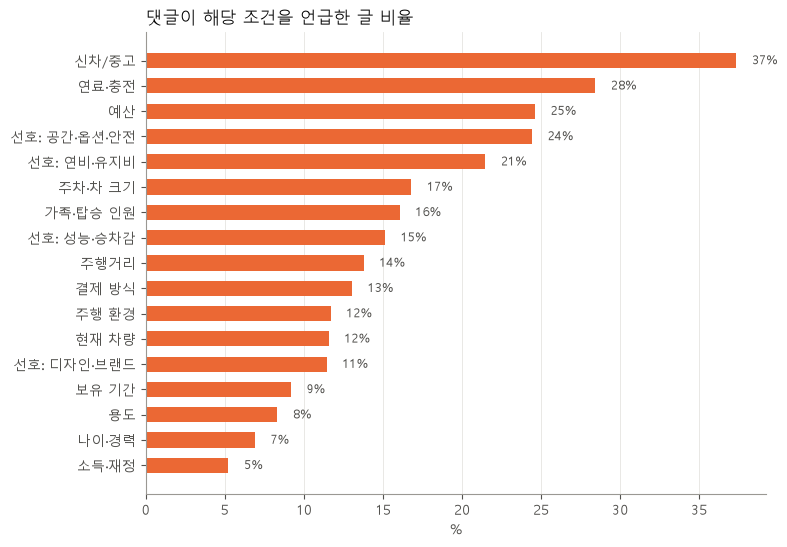

In [17]:
def comment_topics(comments):
    found = set()
    for c in comments:
        if not c["is_op"]:
            found.update(topics_in(c["text"]))
    return found

buy["comment_topics"] = buy["comments"].map(comment_topics)
comment_rate = pd.Series({k: buy["comment_topics"].map(lambda t: k in t).mean() for k in TOPICS}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(comment_rate.index, comment_rate.values * 100, color=ORANGE, height=0.6)
for y, v in enumerate(comment_rate.values):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_title("댓글이 해당 조건을 언급한 글 비율", loc="left")
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
plt.show()

## 6. 자주 나오는 단어

형태소 분석기 [Kiwi](https://github.com/bab2min/kiwipiepy)로 명사(일반·고유)와 영문 단어를 뽑아 센다.
- 글 단위로 센다(한 글에서 여러 번 나와도 1번). 댓글은 한 글의 댓글 전체를 하나로 본다.
- 모델명·줄임말(GV70, 하브 등)은 쪼개지지 않게 사용자 사전에 넣었다.
- 모든 글에 다 나오는 말(차, 고민, 추천, 부탁 …)과 뜻이 없는 말(이상, 가능, 필요 …)은 불용어로 뺐다.
- 같은 뜻의 표기는 합쳤다: 중고차→중고, 하브→하이브리드, 그랜져→그랜저, 새차→신차.

워드클라우드는 인상을 보는 용도이고, 정확한 빈도는 옆의 막대그래프로 읽는다.

In [18]:
from collections import Counter

from kiwipiepy import Kiwi
from wordcloud import WordCloud

kiwi = Kiwi()
USER_WORDS = ["하브", "하이브리드", "전기차", "중고차", "신차", "첫차", "경차", "세컨카", "패밀리카", "인증중고",
              "사회초년생", "승차감", "하차감", "유지비", "감가", "차박", "풀옵", "깡통", "독삼사", "국산차", "수입차",
              "GV60", "GV70", "GV80", "G70", "G80", "G90", "K3", "K5", "K7", "K8", "K9",
              "EV3", "EV4", "EV5", "EV6", "EV9", "아이오닉5", "아이오닉6", "모델3", "모델Y",
              "X3", "X5", "X7", "GLC", "GLE", "E클래스", "C클래스", "S클래스", "XC60", "XC90"]
for w in USER_WORDS:
    kiwi.add_user_word(w, "NNP", 0)

STOP = set("""
차 차량 고민 추천 부탁 생각 정도 구매 구입 질문 문의 형님 형님들 안녕 감사 선배 선배님 선배님들 조언 사람 지금 이번 경우
때문 정말 그냥 진짜 혹시 여기 저희 글 말씀 의견 고견 도움 선택 이유 문제 상황 얘기 이야기 다음 처음 요즘 나중 하나 두 개
쪽 분 님 거 것 수 등 중 때 년 월 일 원 만원 천 정 좀 더 걱정 마음 자동차 어르신 어르신들 행님 행님들 국게 보배 회원
이상 가능 필요 차이 개인 관련 본인 대부분 자체 조금 사항 내용 아래 마지막 최근 기준 이용 진행 포함 사이 시작 정상 일반 입장
부분 전화 방문 사진 변경 결과 시간 확인 정보 사용 가지 하루 자기 이후 이전 동안 그거 이거 저거 무엇 어디 누구 모두 전부
""".split())

NORMALIZE = {"중고차": "중고", "하브": "하이브리드", "그랜져": "그랜저", "키로": "KM", "새차": "신차"}

def nouns(text):
    words = []
    for t in kiwi.tokenize(text or ""):
        if t.tag in ("NNG", "NNP") or (t.tag == "SL" and len(t.form) >= 2):
            w = t.form.upper() if t.tag == "SL" else t.form
            w = NORMALIZE.get(w, w)
            if len(w) >= 2 and w not in STOP:
                words.append(w)
    return words

body_df = Counter(w for text in (buy["title"] + "\n" + buy["body"]) for w in set(nouns(text)))
comment_text = buy["comments"].map(lambda cs: "\n".join(c["text"] or "" for c in cs if not c["is_op"]))
comment_df = Counter(w for text in comment_text for w in set(nouns(text)))
print(f"본문 단어 종류 {len(body_df):,}개, 댓글 단어 종류 {len(comment_df):,}개")

본문 단어 종류 6,503개, 댓글 단어 종류 8,470개


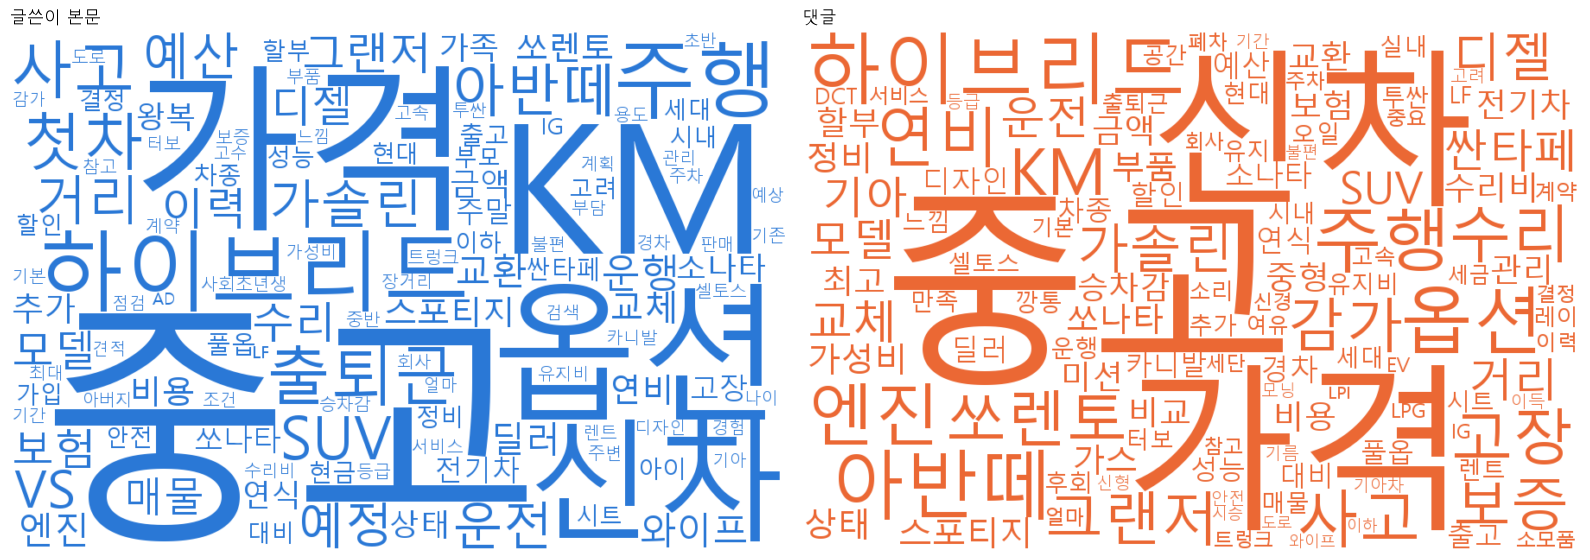

In [19]:
FONT = "C:/Windows/Fonts/malgun.ttf"

def one_color(hex_color):
    return lambda *args, **kwargs: hex_color

def draw(ax, freq, color, title):
    wc = WordCloud(font_path=FONT, width=900, height=600, background_color="white",
                   max_words=120, prefer_horizontal=1.0, color_func=one_color(color), random_state=0)
    ax.imshow(wc.generate_from_frequencies(dict(freq.most_common(120))), interpolation="bilinear")
    ax.set_title(title, loc="left")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
draw(axes[0], body_df, BLUE, "글쓴이 본문")
draw(axes[1], comment_df, ORANGE, "댓글")
plt.tight_layout()
plt.show()

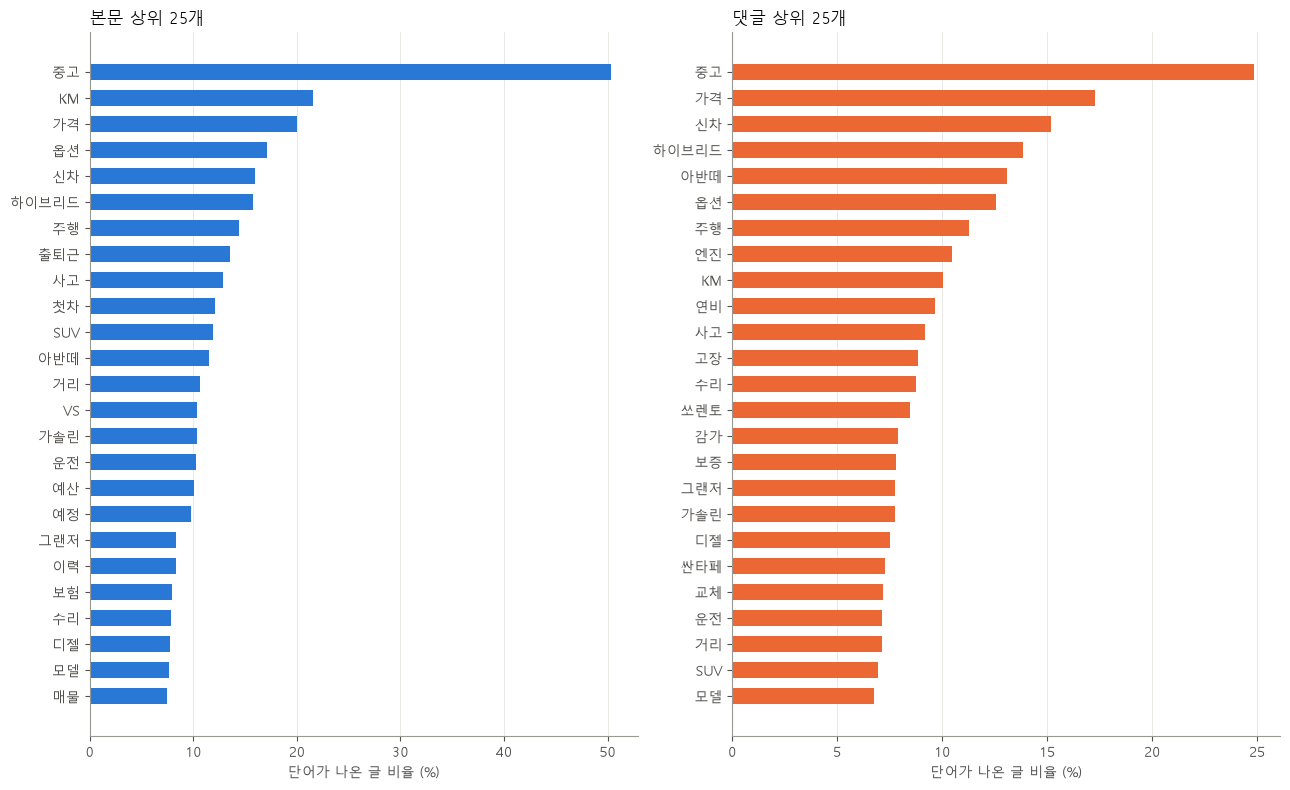

In [20]:
def top_bar(ax, freq, color, title, n=25):
    words, counts = zip(*freq.most_common(n))
    rates = [c / len(buy) * 100 for c in counts]
    ax.barh(words[::-1], rates[::-1], color=color, height=0.6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("단어가 나온 글 비율 (%)")
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
top_bar(axes[0], body_df, BLUE, "본문 상위 25개")
top_bar(axes[1], comment_df, ORANGE, "댓글 상위 25개")
plt.tight_layout()
plt.show()

### 댓글에서 유독 많이 나오는 단어

본문 대비 댓글에서 상대적으로 더 자주 나오는 단어. 추천하는 사람이 끌어오는 관점이다.
두 쪽 모두 글 20건 이상에 나온 단어만 비교한다.

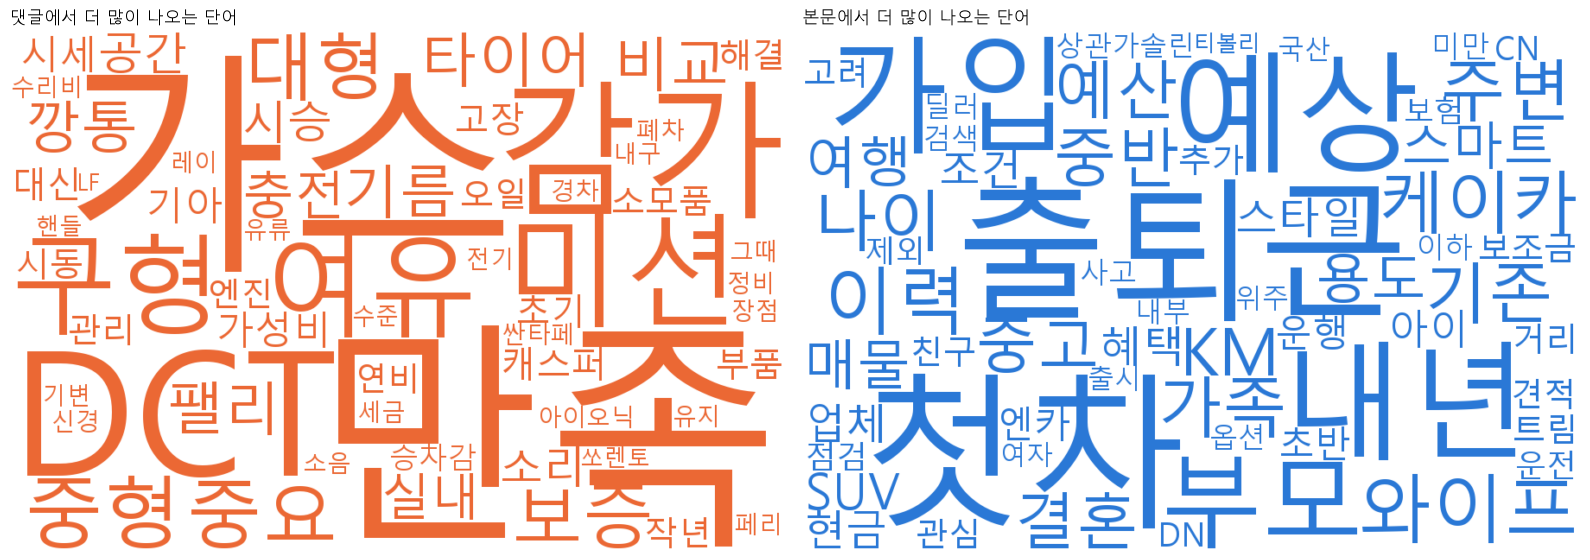

,본문 비율,댓글 비율,댓글/본문
만족,1.4%,4.4%,3.3배
가스,1.9%,6.0%,3.1배
DCT,1.5%,3.8%,2.5배
감가,3.1%,7.9%,2.5배
미션,2.4%,5.5%,2.3배
여유,1.7%,3.8%,2.3배
구형,1.4%,3.0%,2.2배
중형,2.6%,5.7%,2.2배
중요,1.8%,3.6%,2.0배
대형,1.4%,2.8%,2.0배


In [21]:
words = [w for w in set(body_df) | set(comment_df) if body_df[w] + comment_df[w] >= 40 and min(body_df[w], comment_df[w]) >= 20]
lift = pd.DataFrame({
    "본문 비율": [body_df[w] / len(buy) for w in words],
    "댓글 비율": [comment_df[w] / len(buy) for w in words],
}, index=words)
lift["댓글/본문"] = lift["댓글 비율"] / lift["본문 비율"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
draw(axes[0], Counter(lift["댓글/본문"].nlargest(60).to_dict()), ORANGE, "댓글에서 더 많이 나오는 단어")
draw(axes[1], Counter((1 / lift["댓글/본문"]).nlargest(60).to_dict()), BLUE, "본문에서 더 많이 나오는 단어")
plt.tight_layout()
plt.show()

lift.sort_values("댓글/본문", ascending=False).head(20).style.format({"본문 비율": "{:.1%}", "댓글 비율": "{:.1%}", "댓글/본문": "{:.1f}배"})

**읽는 법**
- 본문 쪽(파랑)은 *상황* 단어가 많다: 첫차, 출퇴근, 내년, 예상, 결혼, 와이프, 부모, 가족, 나이, 예산, 용도.
  글쓴이는 자기 처지와 계획을 설명한다.
- 댓글 쪽(주황)은 *결과와 비용* 단어가 많다: 만족, 감가, 여유, 보증, 고장, 수리비, 소모품, 기름, 충전, 미션·DCT, 깡통.
  추천하는 사람은 "사고 나서 만족할지", "유지할 수 있는지"를 따진다.
- 즉 사용자는 상황을 말하고, 조언자는 유지비·고장·감가 같은 장기 비용과 위험으로 답한다.
  9절의 항목별 결과(댓글이 고장·수리와 감가를 본문보다 자주 꺼낸다)와 같은 방향이다.

## 7. 감정 분류

댓글에 담긴 평가가 긍정인지 부정인지를 가벼운 분류 모델로 판별한다.

- **단위는 문장이다.** 댓글 하나에 장점과 단점이 함께 나오는 경우가 많아 문장으로 나눈다(Kiwi의 문장 분리).
- **대상은 댓글이다.** 본문은 글쓴이의 상황 설명이 대부분이고, 평가는 댓글에 있다.
- **모델**: [`Copycats/koelectra-base-v3-generalized-sentiment-analysis`](https://huggingface.co/Copycats/koelectra-base-v3-generalized-sentiment-analysis).
  KoELECTRA-base(파라미터 약 1.1억 개)를 여러 분야의 리뷰 문장으로 학습한 긍정/부정 2분류 모델이다. GPU 없이 이 PC에서 돈다.
- 결과는 `data/cache/`에 저장해 두고, 다시 실행할 때는 새 문장만 계산한다. 처음 실행할 때는 모델을 내려받고 몇 분이 걸린다.

### 7.1 문장으로 나누기

In [22]:
rows = []
for p in posts.itertuples():
    for c in p.comments:
        for s in kiwi.split_into_sents(c["text"] or ""):
            text = " ".join(s.text.split())
            if len(text) >= 2 and re.search("[가-힣]", text):
                rows.append({"post_id": p.id, "is_purchase": p.is_purchase, "is_op": c["is_op"], "text": text})
sents = pd.DataFrame(rows)
print(f"댓글 {sum(len(c) for c in posts['comments']):,}개 → 문장 {len(sents):,}개")
print(f"  글쓴이가 아닌 사람의 문장 {(~sents['is_op']).sum():,}개, 그중 구매 고민 글에 달린 문장 {(~sents['is_op'] & sents['is_purchase']).sum():,}개")
print(f"  문장 길이 중앙값 {sents['text'].str.len().median():.0f}자")

댓글 24,340개 → 문장 42,444개
  글쓴이가 아닌 사람의 문장 31,848개, 그중 구매 고민 글에 달린 문장 18,988개
  문장 길이 중앙값 18자


### 7.2 모델이 이 데이터에 맞는가

모델을 고르기 위해 댓글 문장 69개를 직접 읽고 긍정(P)·부정(N)·중립(U)을 붙였다.
차에 대한 평가가 아니어도 문장의 감정이 분명하면 긍정·부정으로, 사실 전달·질문·단순 조언은 중립으로 붙였다.

In [23]:
SAMPLE = [
    ('U', '케이카 사셈 ㅇㅇ 엔카도 어짜피 일반 상사임 ㅇㅇ'),
    ('U', '직접 차량을 봐야 알수있습니다'),
    ('U', '와이프는 락토핏골드인가 몇년째 먹고있네요'),
    ('P', '부속값은 얼마 안되는군요'),
    ('U', '@간재s 간재님 부모님이 어떤 성향이신지는 모르겠는데 만일 왕래가 잦거나 가족애가 높으신 분이라면..'),
    ('N', '누가 운전했는지 연습용 차로 썼나 봅니다.'),
    ('U', '스테이모드있는 플레오스는 괜찮겠지만 그게아니면 ccnc 긴게 더 편하실걸요'),
    ('P', '큰문제는 없어보이는데 수리비가 98밖에 안되는게 더 놀랍네요'),
    ('P', '감가방어 2황이 레이랑 아반떼입니다'),
    ('U', '그냥 다음 주인한테 잘 타고 다니라는 의미로..'),
    ('U', '저당잡혀있으면요'),
    ('P', '싼타페가 생각보다 승차감이 좋거든요'),
    ('U', '뭐 애초에 저가형 라인업 타이어를 찾는 사람들이 성능찾아오는것도 아니긴하지만..'),
    ('U', '버는 것보다 꾸미거나(옷, 미용든) 생활비가 더 많이 나가는 애들이라고'),
    ('U', '단양도 그럭저럭 1박코스 짜지더군요'),
    ('U', '그것도 안해준다하면 수원가야겠죠'),
    ('P', '차로가 잘보임.'),
    ('P', 'SUV가 땡기시면 GV80쿠페.. (베링블루 컬러에 22인치휠 조합 굿~)'),
    ('P', '싼타페타시다 가시면 엄청 느끼실겁니다'),
    ('N', '겨울철 진동에다 엔진오일에 연료 홉합이슈에 DPF 까지...'),
    ('U', '예전에 250주고 사서 3년탄적 있는데여'),
    ('N', '하부부식은 보증수리대상이아니라..'),
    ('N', '전 비추 합니다..'),
    ('N', 'Sm 에서 거릅니다.'),
    ('U', '매일매일 와인딩 하며 잡아 제끼는 거 아닌 이상 체감 X. 정 불안하시면 순정타이어 허용 규격 확인해 보시고요. (차량설명서, 운전석 프레임 하단 스티커 등등)'),
    ('U', '겨울에 윈터타이어를 장착해봄이 어떠신가여'),
    ('U', '재벌이되면 이동식 낚시차하나 마련하고싶네여 ㄷㄷ'),
    ('U', '@ndmdl78j 저음 1뱐에 알리에서 17만원이면 삽니다'),
    ('N', '여기반말쓰는곳 아닙니다'),
    ('N', '그리고 다자녀아빠라 ㅠㅠ 준대형세단으론 지금 가고싶지 않아요..ㅠㅠ'),
    ('N', '사지마셈....'),
    ('U', '디젤은 연료필터가 생명과도 같다고 생각합니다'),
    ('N', '이전 자체가 안될건데요'),
    ('P', '스포티지 LPG 새차사세요'),
    ('N', '모하비 타시면 후회할텐데요?'),
    ('N', 'EV5 배터리 중국산 아닌가요???'),
    ('P', '장거리 고속주행 자주하시는 분들은 필터만 잘 갈아도 손델거 없습니다'),
    ('P', '계속 아N을 가지고 있는 이유죵.. ㅎㅎ'),
    ('N', '이런곳에 아무것도 모르는 애를 카시트 장착하고 태웠다니 하는 후회 때문에 바로 팔아버리고 팰리8인승 사서 2열에 3명 태우고 다닙니다.'),
    ('N', '어쩔수 없이 카니발 하시려면 3세대 디젤은 절대 피하세요.'),
    ('U', '그 정도는 쓰시면 됨.'),
    ('P', '만천하스카이워크랑 고수동굴 가볼만 http://m.blog.naver.com/k-traveler-/223098872755'),
    ('U', '아무 상관 없습니다'),
    ('N', '아직은 중국산 배터리는 아닌것 같다는 개인적인 의견이요..'),
    ('U', '보증이 남은차를 산다'),
    ('U', '그냥 새차가 답입니다'),
    ('U', '돈이 모자르면 모자른데로 가격이 저렴한 차를 사시면 됩니다.'),
    ('U', '중고차보증보험으로 수리를 했는데 부품을 구매해서 수리를 했다는거죠?'),
    ('U', '5N을 타든지..'),
    ('N', '카니발 데일리로 끌고다니기엔 좀 부담스럽습니다'),
    ('U', '동풍이 기부 받섭니다'),
    ('N', '님 운전성격과 발탓을 해야함'),
    ('U', 'ㅎ 제가 21년식?'),
    ('U', '그냥 타던차 타라...'),
    ('U', '사진으로는 깨끗해보이는데 육안으로 한번 더보세요'),
    ('P', '제네시스수지 가서 G70슈팅브레이크 바트나그레이 보고 칼러가 넘 맘에 들어 돈 있으면 당장이라도 사고 싶은 충동구매 느꼈네요'),
    ('U', '시간에 쫒기는건 같지만.'),
    ('N', '저도 찜 해논것들 보면 오래 안팔리는 차들이 가격 올리더라구요'),
    ('N', '가격 괜찮다 싶은건 판매완료 되고 지들 안팔리는 동안의 이자 등등 손해 본 금액 만큼 걍 올려버리는듯ㅋㅋㅋ'),
    ('U', '그럼 상사의 경우 상품용이라 뜨니까요.'),
    ('U', '본인명의, 할부X 이 두가지만 지키세요'),
    ('U', '비싸게 산건 사기라고 보기엔 .... ㅠㅠ'),
    ('P', '그래도 심적인 불안감은 없지유'),
    ('U', '부글부글 잘 끓으셨군요 ㅋㅋㅋㅋㅋㅋㅋㅋ'),
    ('U', '자동차 보험료 10만원이라.....'),
    ('N', '최소 500이상 싼거 아니면 메리트 없음'),
    ('U', '두대다 2.5 awd기준'),
    ('U', '근데 웃기는게 울나라에 파는게 다 똑같습니다'),
    ('N', '저 아시는 분도 고집 부리다 부모님한테 욕 디지게 먹고 결국 친척이 하는 브랜드 사셨어요'),
]
sample = pd.DataFrame(SAMPLE, columns=["label", "text"])
print(sample["label"].map({"P": "긍정", "N": "부정", "U": "중립"}).value_counts().to_string())

label
중립    36
부정    20
긍정    13


In [24]:
MODEL = "Copycats/koelectra-base-v3-generalized-sentiment-analysis"
CACHE = Path(f"data/cache/sentiment_{DAY}.json")


def classify(texts, batch_size=64):
    """문장마다 긍정일 확률을 돌려준다."""
    import os
    os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    from transformers.utils import logging
    logging.set_verbosity_error()
    logging.disable_progress_bar()

    tokenizer = AutoTokenizer.from_pretrained(MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL).eval()
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))  # 길이가 비슷한 문장끼리 묶어야 빠르다
    prob = np.zeros(len(texts))
    with torch.no_grad():
        for start in range(0, len(order), batch_size):
            index = order[start:start + batch_size]
            encoded = tokenizer([texts[i] for i in index], padding=True, truncation=True, max_length=128, return_tensors="pt")
            prob[index] = torch.softmax(model(**encoded).logits, dim=-1)[:, 1].numpy()
    return prob


cache = json.loads(CACHE.read_text(encoding="utf-8")) if CACHE.exists() else {}
todo = sorted((set(sents["text"]) | set(sample["text"])) - set(cache))
if todo:
    cache.update(zip(todo, classify(todo).round(4).tolist()))
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    CACHE.write_text(json.dumps(cache, ensure_ascii=False), encoding="utf-8")
sents["p_pos"] = sents["text"].map(cache)
sample["p_pos"] = sample["text"].map(cache)
print(f"새로 계산한 문장 {len(todo):,}개, 저장해 둔 결과 {len(cache):,}개")

새로 계산한 문장 0개, 저장해 둔 결과 40,460개


모델은 문장마다 "긍정일 확률"을 낸다. 이 모델에는 중립이 없어서, 확률이 한쪽으로 충분히 쏠린 문장만 긍정·부정으로 보고 나머지는 "중립·불확실"로 둔다.
기준을 얼마나 엄하게 잡을지 직접 붙인 레이블과 비교한다.

- 정밀도: 모델이 긍정(부정)이라고 한 문장 중 실제로 긍정(부정)인 비율
- 재현율: 실제 긍정(부정) 문장 중 모델이 찾아낸 비율

In [25]:
def judge(p, cut):
    return np.select([p >= cut, p <= 1 - cut], ["P", "N"], "U")


def score(cut):
    pred = judge(sample["p_pos"], cut)
    out = {"정확도": (pred == sample["label"]).mean()}
    for key, name in [("P", "긍정"), ("N", "부정")]:
        hit = ((pred == key) & (sample["label"] == key)).sum()
        out[f"{name} 판정 수"] = (pred == key).sum()
        out[f"{name} 정밀도"] = hit / max(1, (pred == key).sum())
        out[f"{name} 재현율"] = hit / (sample["label"] == key).sum()
    out["전체 문장 중 긍정"] = (sents["p_pos"] >= cut).mean()
    out["전체 문장 중 부정"] = (sents["p_pos"] <= 1 - cut).mean()
    return out


cuts = pd.DataFrame({f"{cut:.2f} 이상": score(cut) for cut in [0.5, 0.9, 0.95, 0.98]}).T
print(f"모두 중립이라고 답했을 때의 정확도 {(sample['label'] == 'U').mean():.0%}")
cuts.style.format("{:.0%}").format("{:.0f}", subset=["긍정 판정 수", "부정 판정 수"])

모두 중립이라고 답했을 때의 정확도 52%


,정확도,긍정 판정 수,긍정 정밀도,긍정 재현율,부정 판정 수,부정 정밀도,부정 재현율,전체 문장 중 긍정,전체 문장 중 부정
0.50 이상,42%,25,40%,77%,44,43%,95%,51%,49%
0.90 이상,64%,4,75%,23%,21,62%,65%,15%,17%
0.95 이상,65%,3,67%,15%,12,83%,50%,8%,10%
0.98 이상,64%,1,100%,8%,7,100%,35%,3%,5%


다른 후보도 같은 69문장으로 시험했다(2026-11-27, 이 Notebook 밖에서 한 번 실행한 결과).

| 모델 | 파라미터 | 분류 | 정확도 | 속도 (문장/초, CPU) |
|---|---|---|---|---|
| `Copycats/koelectra-base-v3-generalized-sentiment-analysis` | 1.1억 | 긍정/부정, 확률 0.9 이상만 | 64% | 62 |
| `nlp04/korean_sentiment_analysis_kcelectra` | - | 감정 11가지를 긍정·중립·부정으로 묶음 | 61% | 71 |
| `tabularisai/multilingual-sentiment-analysis` | 1.4억 | 5단계 (중립 포함) | 52% | 90 |
| `clapAI/modernBERT-base-multilingual-sentiment` | 1.5억 | 긍정/중립/부정 | 49% | 2 |
| `searle-j/kote_for_easygoing_people` | - | 감정 44가지를 긍정·중립·부정으로 묶음 | 48% | 63 |
| `daekeun-ml/koelectra-small-v3-nsmc` | 0.14억 | 긍정/부정, 확률 0.9 이상만 | 46% | 398 |
| `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | 1.4억 | 긍정/중립/부정 | 26% | 89 |

- 가장 가벼운 모델(KoELECTRA-small, 영화 리뷰로 학습)은 빠르지만 "두대다 2.5 awd기준" 같은 중립 문장을 강한 부정으로 판정해, 모두 중립이라고 답한 것보다 정확도가 낮았다.
- 커뮤니티 댓글은 절반이 평가가 아닌 사실 전달·질문·조언이다. 리뷰로 학습한 모델은 이런 문장을 긍정이나 부정 어느 한쪽으로 보낸다.
- 그래서 확률이 크게 쏠린 문장만 쓴다. 표본이 69문장뿐이라 위 수치는 대략적인 크기로만 읽는다.

### 7.3 판정 결과

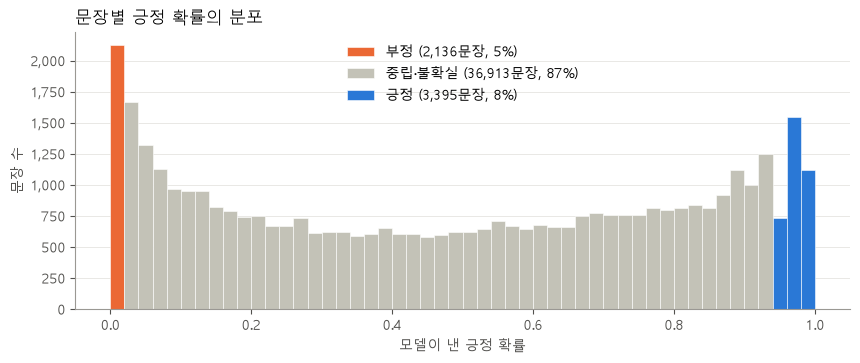

label,문장 수,긍정,중립·불확실,부정
전체 문장,"42,444",8.0%,87.0%,5.0%
글쓴이가 아닌 사람,"31,848",7.1%,87.3%,5.6%
글쓴이,"10,596",10.8%,86.0%,3.3%
구매 고민 글 (글쓴이 아님),"18,988",7.6%,87.4%,5.0%


In [26]:
POS_CUT, NEG_CUT = 0.95, 0.02   # 긍정은 확률 0.95 이상, 부정은 0.02 이하
sents["label"] = np.select([sents["p_pos"] >= POS_CUT, sents["p_pos"] <= NEG_CUT], ["긍정", "부정"], "중립·불확실")
LABELS = ["긍정", "중립·불확실", "부정"]
LABEL_COLOR = {"긍정": BLUE, "중립·불확실": GRAY, "부정": ORANGE}

fig, ax = plt.subplots(figsize=(10, 3.6))
edges = np.linspace(0, 1, 51)
for name, mask in [("부정", sents["p_pos"] <= NEG_CUT), ("중립·불확실", (sents["p_pos"] > NEG_CUT) & (sents["p_pos"] < POS_CUT)),
                   ("긍정", sents["p_pos"] >= POS_CUT)]:
    ax.hist(sents.loc[mask, "p_pos"], bins=edges, color=LABEL_COLOR[name], edgecolor="white", linewidth=0.4,
            label=f"{name} ({mask.sum():,}문장, {mask.mean():.0%})")
ax.set_xlabel("모델이 낸 긍정 확률")
ax.set_ylabel("문장 수")
ax.set_title("문장별 긍정 확률의 분포", loc="left")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, loc="upper center")
ax.grid(axis="x", visible=False)
plt.show()

groups = {"전체 문장": sents, "글쓴이가 아닌 사람": sents[~sents["is_op"]], "글쓴이": sents[sents["is_op"]],
          "구매 고민 글 (글쓴이 아님)": sents[~sents["is_op"] & sents["is_purchase"]]}
share = pd.DataFrame({name: frame["label"].value_counts(normalize=True) for name, frame in groups.items()}).T[LABELS]
share.insert(0, "문장 수", [len(frame) for frame in groups.values()])
share.style.format("{:.1%}").format("{:,}", subset=["문장 수"])

기준은 긍정 0.95 이상, 부정 0.02 이하로 잡았다. 열에 아홉 가까운 문장이 "중립·불확실"로 남는다.

- 부정 기준이 더 엄한 것은, 이 모델이 짧고 단정적인 중립 문장("그냥 새차가 답입니다")을 부정으로 보내는 경향이 있어서다(7.2절).
- 기준을 정할 때 확률 구간별로 문장을 20개씩 읽어 보았다. 확률 0.02~0.05 구간의 문장은 절반 넘게 중립이었고("보증대상이면 수리받아야죠"),
  0.90~0.95 구간도 절반 정도만 긍정이었다.

판정이 맞는지는 문장을 읽어서 확인한다. 아래에서는 구매 고민 글에 다른 사람이 단 문장만 쓰고, "감사합니다", "축하합니다" 같은 인사말은 뺀다.
인사말은 긍정으로 판정되지만 차에 대한 평가가 아니다.

In [27]:
GREETING = r"감사|고맙|축하|수고하|수고\s?많|화이팅|파이팅|안전\s?운전|안운|[고구]\s?갑니다"
opinions = sents[~sents["is_op"] & sents["is_purchase"]]
is_greeting = opinions["text"].str.contains(GREETING)
print(f"구매 고민 글에 다른 사람이 단 문장 {len(opinions):,}개 중 인사말 {is_greeting.sum():,}개를 뺀다 "
      f"(인사말의 {(opinions.loc[is_greeting, 'label'] == '긍정').mean():.0%}가 긍정 판정)")
opinions = opinions[~is_greeting].reset_index(drop=True)
print(opinions["label"].value_counts().reindex(LABELS).rename("문장 수").to_frame().T.to_string())
print()
readable = opinions[opinions["text"].str.len().between(10, 70)]
for name in LABELS:
    print(f"[{name}]")
    print(readable.loc[readable["label"] == name, "text"].sample(15, random_state=1).to_string(index=False))
    print()

구매 고민 글에 다른 사람이 단 문장 18,988개 중 인사말 121개를 뺀다 (인사말의 46%가 긍정 판정)
label    긍정  중립·불확실   부정
문장 수   1391   16537  939

[긍정]
제 친구들과 여행삼아 제 차량으로 강원도 갔었는데 다들 승차감 좋다고 했습니다.
                            8기통 대배기량 타보고 싶네요
                              감가도 크고 하체도 좋고.
                하드론 ZS,ZR쓰는데 순정보다 제동력이 좋습니다.
                                  합리화 좋습니다 ㅎ
                                둘 다 넓고 좋습니다.
                                 흰색 선루프 = 진리
                             LF쏘나타 LPG 추천드려요
                  큰차 필요없으시면 Q8도 요즘 할인율 좋습니다~
                           간만에 보배다운글 읽었습니다..
                                ig페리 부터 충분해요
                          그래서 추천 2개 삽입했습니닿ㄷㄷ
                         필터를 오래 안 갈고 사용가능하죠.
               1.5배 차이도 아니고 일주일만 지나면 적응 됩니다.
      @조뽀또 지금 시내만 타는데 평균 7~8km/L 나와주네요... ^^

[중립·불확실]
                                           주행거리때문에 하이브리드요 ??
본인 차량과 버스를 맞바꿔가며 주차해두고 저도 몇번 사진 찍어서 신고 하고 그랬었는데 아직도 그러나 봅니다.
               헤드가스켓 누유는 흡기호스 탈거후 메니폴더 안쪽으로 내시경 찔러보면 답 나옵니다.
              

위 표본을 읽어 보면 다음과 같다.

- **긍정** 15개 중 7개는 분명한 긍정이고("둘 다 넓고 좋습니다"), 3개는 약한 긍정이다. 나머지는 중립이거나 비꼬는 말이다("합리화 좋습니다 ㅎ").
- **부정** 15개 중 12개가 부정이다. 나머지는 사실을 전하는 중립 문장이다("제조사 교환주기는 6만마다 일겁니다").
- **중립·불확실**에는 실제 중립 문장이 많지만 "여유된다면 현금 적극 추천!"처럼 평가가 담긴 문장도 섞여 있다. 놓치는 문장이 많다는 뜻이다.

판정된 문장은 대체로 방향이 맞지만 일부이고, 문장 하나하나의 판정을 믿기보다 수백 문장을 모아 경향을 보는 용도로 쓴다.

## 8. 긍정·부정 문장에 많이 나오는 키워드

구매 고민 글에 글쓴이가 아닌 사람이 단 댓글 문장에서 명사와 형용사를 뽑아, 긍정 문장과 부정 문장에 각각 얼마나 나오는지 센다.

- 명사는 6절과 같은 방법(일반·고유명사와 영문 단어, 같은 불용어)으로 뽑는다. 형용사는 기본형("좋다", "비싸다")으로 센다.
- 문장 단위로 센다(한 문장에서 여러 번 나와도 1번).

### 8.1 자주 나오는 키워드

In [28]:
ADJ_STOP = set("있다 없다 같다 그렇다 어떻다 이렇다 저렇다 아니다".split())


def keywords(text):
    found = set()
    for t in kiwi.tokenize(text):
        if t.tag in ("NNG", "NNP") or (t.tag == "SL" and len(t.form) >= 2):
            w = t.form.upper() if t.tag == "SL" else t.form
            w = NORMALIZE.get(w, w)
            if len(w) >= 2 and w not in STOP:
                found.add(("명사", w))
        elif t.tag.startswith("VA"):
            w = t.form + "다"
            if w not in ADJ_STOP:
                found.add(("형용사", w))
    return found


opinions["keywords"] = opinions["text"].map(keywords)
n_label = opinions["label"].value_counts()
freq = {(label, kind): Counter(w for kws in opinions.loc[opinions["label"] == label, "keywords"] for k, w in kws if k == kind)
        for label in LABELS for kind in ["명사", "형용사"]}
print(n_label.reindex(LABELS).rename("문장 수").to_frame().T.to_string())

label    긍정  중립·불확실   부정
문장 수   1391   16537  939


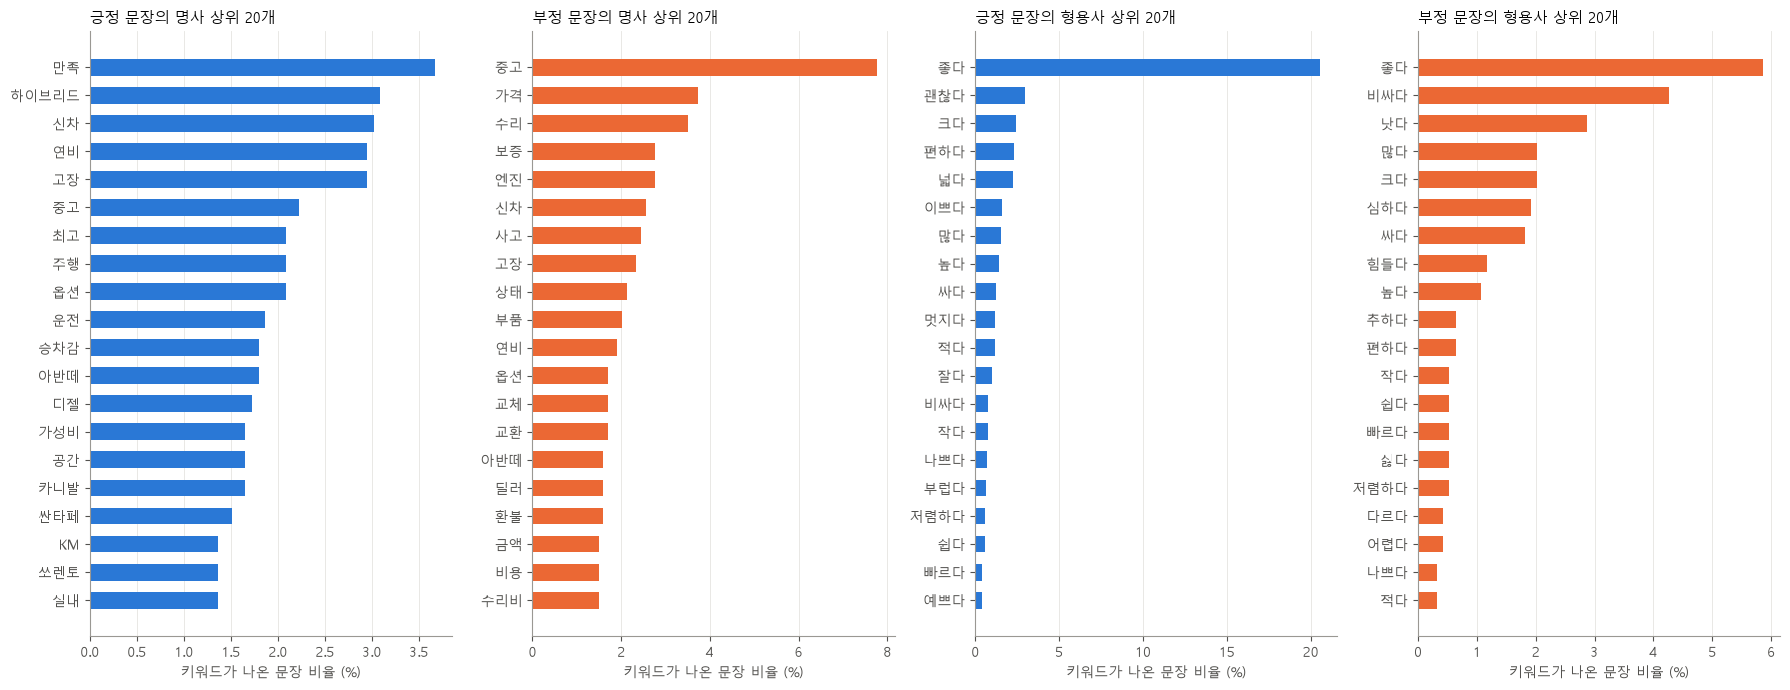

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(18, 7))
for ax, (label, kind) in zip(axes, [("긍정", "명사"), ("부정", "명사"), ("긍정", "형용사"), ("부정", "형용사")]):
    words, counts = zip(*freq[(label, kind)].most_common(20))
    rates = [c / n_label[label] * 100 for c in counts]
    ax.barh(words[::-1], rates[::-1], color=LABEL_COLOR[label], height=0.6)
    ax.set_title(f"{label} 문장의 {kind} 상위 20개", loc="left", fontsize=11)
    ax.set_xlabel("키워드가 나온 문장 비율 (%)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

자주 나오는 키워드는 긍정과 부정에 겹치는 것이 많다. "가격", "중고" 같은 말은 어느 쪽에나 나온다.
어느 쪽에 **더 치우쳐** 나오는지를 따로 본다.

### 8.2 한쪽에 치우친 키워드

키워드마다 `긍정 문장에 나온 비율 ÷ 부정 문장에 나온 비율`을 구한다. 1보다 크면 긍정 문장에 더 자주 나온다는 뜻이다.
긍정·부정 문장을 합쳐 15번 이상 나온 키워드만 쓰고, 한쪽에 한 번도 안 나온 키워드도 계산되도록 양쪽에 0.5씩 더했다.

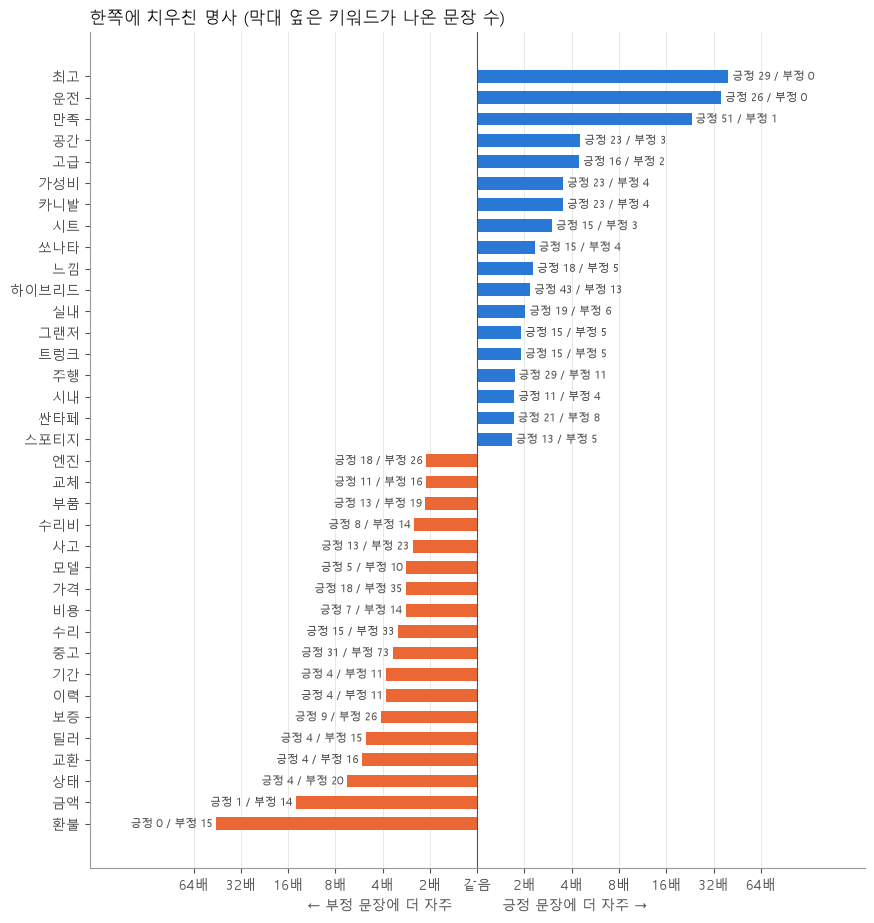

In [30]:
def lean(kind, min_count=15):
    pos, neg = freq[("긍정", kind)], freq[("부정", kind)]
    table = pd.DataFrame({"긍정 문장": pd.Series(pos), "부정 문장": pd.Series(neg)}).fillna(0).astype(int)
    table = table[table.sum(axis=1) >= min_count]
    table["긍정 비율"] = (table["긍정 문장"] + 0.5) / (n_label["긍정"] + 1)
    table["부정 비율"] = (table["부정 문장"] + 0.5) / (n_label["부정"] + 1)
    table["치우침"] = np.log2(table["긍정 비율"] / table["부정 비율"])
    return table.sort_values("치우침")


def lean_chart(kind, n=18):
    table = lean(kind)
    side = table if len(table) <= 2 * n else pd.concat([table.head(n), table.tail(n)])
    y = np.arange(len(side))
    fig, ax = plt.subplots(figsize=(10, 0.26 * len(side) + 1.5))
    ax.barh(y, side["치우침"], color=[BLUE if v > 0 else ORANGE for v in side["치우침"]], height=0.6)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    for i, (lean_value, pos, neg) in enumerate(zip(side["치우침"], side["긍정 문장"], side["부정 문장"])):
        ax.text(lean_value + (0.08 if lean_value > 0 else -0.08), i, f"긍정 {pos:,} / 부정 {neg:,}",
                va="center", ha="left" if lean_value > 0 else "right", fontsize=8, color="#52514e")
    reach = int(np.ceil(side["치우침"].abs().max()))
    ticks = list(range(-reach, reach + 1))
    ax.set_xticks(ticks, [f"{2 ** abs(t)}배" if t else "같음" for t in ticks])
    ax.set_xlim(-reach - 2.2, reach + 2.2)
    ax.set_yticks(y, side.index)
    ax.set_xlabel("← 부정 문장에 더 자주          긍정 문장에 더 자주 →")
    ax.set_title(f"한쪽에 치우친 {kind} (막대 옆은 키워드가 나온 문장 수)", loc="left")
    ax.grid(axis="y", visible=False)
    plt.show()
    return table


noun_lean = lean_chart("명사")

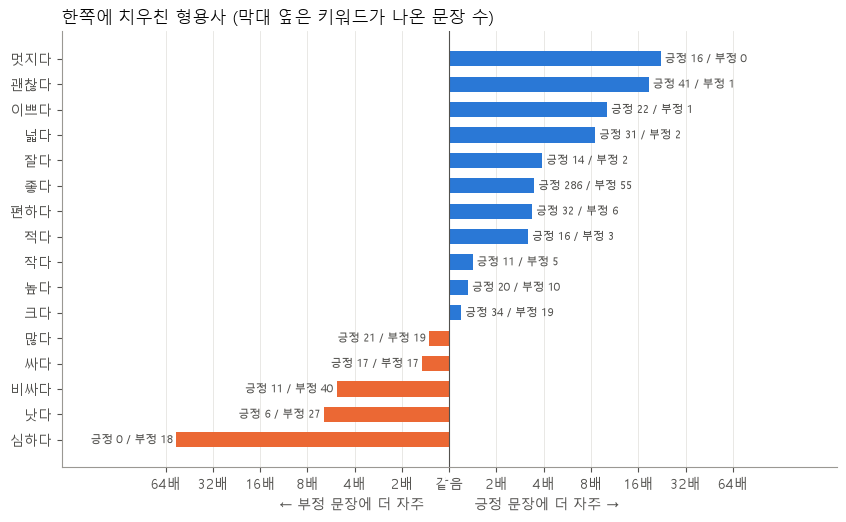

In [31]:
adj_lean = lean_chart("형용사", n=14)

In [32]:
good = opinions[opinions["text"].str.contains("좋")]
negated = good["text"].str.contains(r"안\s?좋|좋지|좋진|좋은\s?게\s?아니|좋을\s?게\s?없|좋을\s?것\s?없")
print("['좋'이 들어간 문장 중 '안 좋다', '좋지 않다'처럼 부정하는 꼴의 비율]")
print(negated.groupby(good["label"]).agg(["mean", "size"]).reindex(LABELS).rename(columns={"mean": "부정하는 꼴", "size": "문장 수"}).to_string(
    formatters={"부정하는 꼴": "{:.0%}".format}))

['좋'이 들어간 문장 중 '안 좋다', '좋지 않다'처럼 부정하는 꼴의 비율]
       부정하는 꼴  문장 수
label              
긍정         1%   297
중립·불확실     9%   929
부정        43%    56


In [33]:
def side_table(table, n=15):
    table = table.assign(배율=2 ** table["치우침"].abs())
    pos = table.sort_values("치우침", ascending=False).head(n).reset_index(names="긍정 쪽 키워드")
    neg = table.head(n).reset_index(names="부정 쪽 키워드")
    out = pd.concat([pos[["긍정 쪽 키워드", "긍정 문장", "부정 문장", "배율"]],
                     neg[["부정 쪽 키워드", "긍정 문장", "부정 문장", "배율"]].rename(
                         columns={"긍정 문장": "긍정 문장 ", "부정 문장": "부정 문장 ", "배율": "배율 "})], axis=1)
    out.index = range(1, n + 1)
    return out.style.format({"배율": "{:.1f}배", "배율 ": "{:.1f}배"})


side_table(noun_lean)

,긍정 쪽 키워드,긍정 문장,부정 문장,배율,부정 쪽 키워드,긍정 문장,부정 문장,배율
1,최고,29,0,39.8배,환불,0,15,45.9배
2,운전,26,0,35.8배,금액,1,14,14.3배
3,만족,51,1,23.2배,상태,4,20,6.7배
4,공간,23,3,4.5배,교환,4,16,5.4배
5,고급,16,2,4.5배,딜러,4,15,5.1배
6,카니발,23,4,3.5배,보증,9,26,4.1배
7,가성비,23,4,3.5배,이력,4,11,3.8배
8,시트,15,3,3.0배,기간,4,11,3.8배
9,쏘나타,15,4,2.3배,중고,31,73,3.5배
10,느낌,18,5,2.3배,수리,15,33,3.2배


- **긍정 쪽 명사**: "만족", "최고" 같은 평가어, "공간", "실내", "트렁크", "시트" 같은 쓰임새, "가성비", "하이브리드", 그리고 카니발·쏘나타·그랜저 같은 모델 이름이다.
- **부정 쪽 명사**: "환불", "딜러", "이력", "상태", "보증"처럼 거래와 차 상태에 관한 말, "수리", "수리비", "교환", "비용", "금액"처럼 고치는 데 드는 돈에 관한 말이다.
- 긍정은 "차가 어떤가"에, 부정은 "사고 나서 무슨 일이 생기나"에 몰려 있다.
- **형용사**는 "좋다", "괜찮다", "비싸다"처럼 평가하는 말 그 자체라서 모델의 판정과 거의 겹친다.
  "좋다"는 부정 문장에서도 가장 많이 나오는 형용사인데, 부정 문장에서는 "안 좋다", "좋지 않다"처럼 부정하는 꼴이 많다(위 표). 단어 하나만으로는 방향을 알 수 없다.
- 키워드마다 문장이 수십 개 수준이라 순위 하나하나보다 묶음으로 읽는다. 항목으로 묶어서 다시 본다(9절).

## 9. 차를 살 때 무엇을 중점으로 보나

차의 어떤 점을 따지는지 항목으로 묶어, (1) 얼마나 자주 이야기되는지와 (2) 긍정·부정 중 어느 쪽으로 이야기되는지를 본다.
항목은 6절과 8절에 많이 나온 말을 바탕으로 정규식으로 만들었다. 한 문장이 여러 항목에 걸릴 수 있다.

In [34]:
ASPECTS = {
    "가격·가성비": r"가격|가성비|비싸|비쌈|(?<!비)싸[다게서고네]|저렴|돈값|할인|시세|\d\s?만\s?원|천만",
    "연비·유지비": r"연비|유지비|기름값|기름\s?값|유류비|보험료|자동차세|세금|충전비|전비|유지\s?비용",
    "고장·내구성·수리": r"고장|결함|잔고장|내구|수리|정비|누유|리콜|부식|하자|이슈|보증|수리비|부품|a/s|(?<![a-z])as(?![a-z])",
    "감가·되팔 때": r"감가|중고\s?값|잔존|되팔|방어",
    "승차감·정숙성": r"승차감|정숙|소음|시끄|조용|진동|하체|서스|안락|푹신|딱딱",
    "주행 성능": r"출력|가속|마력|토크|힘이|핸들링|코너|주행감|성능(?!\s?(지|점검|기록|보험|보증))|밟",
    "공간·실용성": r"공간|트렁크|2열|3열|실내(?!\s?디자인)|적재|차박|넓|좁",
    "옵션·편의 장비": r"옵션|통풍|열선|크루즈\s?(컨트롤|기능)|스마트\s?크루즈|hud|어라운드|편의|풀옵|깡통|내비|카플레이",
    "안전": r"안전(?!\s?운전)|adas|에어백|충돌|긴급\s?제동",
    "디자인": r"디자인|외관|이쁘|예쁘|멋|못생|생긴",
    "브랜드·급": r"브랜드|하차감|수입차|국산차|독일|감성|급이|급\s?차이|체급|윗급|한\s?급",
    "크기·주차": r"주차|차폭|전장|크기|사이즈|골목",
}
ASPECT_RE = {k: re.compile(v, re.I) for k, v in ASPECTS.items()}


def aspects_in(text):
    return [k for k, r in ASPECT_RE.items() if r.search(text or "")]


buy["body_aspects"] = (buy["title"] + "\n" + buy["body"]).map(aspects_in)
buy["comment_aspects"] = buy["comments"].map(
    lambda cs: sorted({a for c in cs if not c["is_op"] for a in aspects_in(c["text"])}))
opinions["aspects"] = opinions["text"].map(aspects_in)

aspect = pd.DataFrame({
    "본문에 나온 글": {a: buy["body_aspects"].map(lambda v: a in v).mean() for a in ASPECTS},
    "댓글에 나온 글": {a: buy["comment_aspects"].map(lambda v: a in v).mean() for a in ASPECTS},
})
for label in LABELS:
    aspect[f"{label} 문장"] = {a: (opinions["aspects"].map(lambda v: a in v) & (opinions["label"] == label)).sum() for a in ASPECTS}
aspect["댓글 문장"] = aspect[[f"{label} 문장" for label in LABELS]].sum(axis=1)
aspect["부정 비중"] = aspect["부정 문장"] / (aspect["긍정 문장"] + aspect["부정 문장"])
aspect = aspect.sort_values("댓글에 나온 글", ascending=False)
overall = n_label["부정"] / (n_label["긍정"] + n_label["부정"])
print(f"구매 고민 글 {len(buy):,}건, 글쓴이가 아닌 사람의 댓글 문장 {len(opinions):,}개")
print(f"항목이 하나라도 나온 문장 {opinions['aspects'].map(bool).mean():.0%}, 전체 문장의 부정 비중 {overall:.0%}")

구매 고민 글 1,626건, 글쓴이가 아닌 사람의 댓글 문장 18,867개
항목이 하나라도 나온 문장 25%, 전체 문장의 부정 비중 40%


### 9.1 얼마나 자주 이야기되나

구매 고민 글 가운데 본문(글쓴이)과 댓글(다른 사람)에 각 항목이 나온 글의 비율이다.

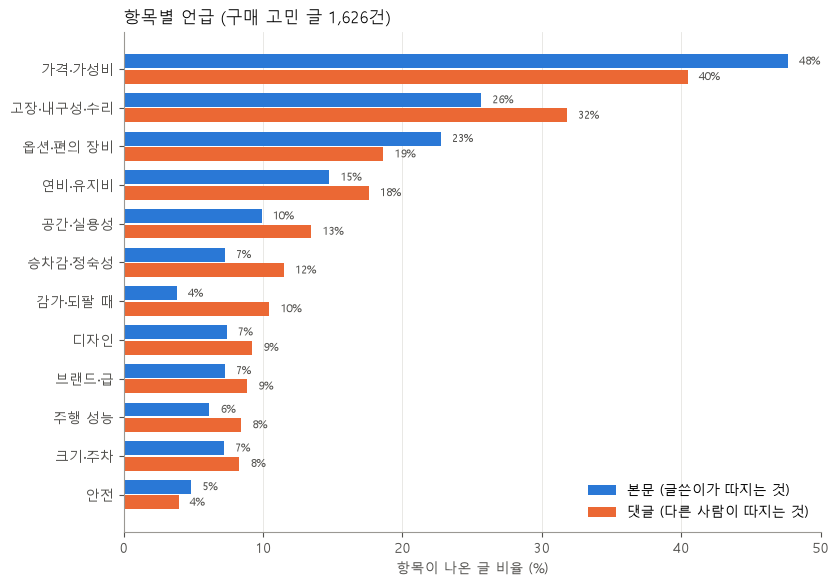

In [35]:
order = aspect.index[::-1]
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(y + 0.2, aspect.loc[order, "본문에 나온 글"] * 100, height=0.36, color=BLUE, label="본문 (글쓴이가 따지는 것)")
ax.barh(y - 0.2, aspect.loc[order, "댓글에 나온 글"] * 100, height=0.36, color=ORANGE, label="댓글 (다른 사람이 따지는 것)")
for i, a in enumerate(order):
    ax.text(aspect.loc[a, "본문에 나온 글"] * 100 + 0.8, i + 0.2, f"{aspect.loc[a, '본문에 나온 글']:.0%}", va="center", fontsize=8, color="#52514e")
    ax.text(aspect.loc[a, "댓글에 나온 글"] * 100 + 0.8, i - 0.2, f"{aspect.loc[a, '댓글에 나온 글']:.0%}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, order)
ax.set_xlabel("항목이 나온 글 비율 (%)")
ax.set_title(f"항목별 언급 (구매 고민 글 {len(buy):,}건)", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

- **가격·가성비**가 본문과 댓글 모두에서 가장 많이 나온다. 구매 고민 글의 절반 가까이가 본문에서 가격을 이야기한다.
- 그다음은 **고장·내구성·수리**이고, 글쓴이보다 댓글이 더 자주 꺼낸다.
- **감가**, **승차감·정숙성**, **공간**도 댓글에서 더 자주 나온다. 특히 감가는 글쓴이는 거의 쓰지 않는데 댓글이 꺼내는 항목이다.
- **안전**, **크기·주차**, **주행 성능**, **브랜드·급**, **디자인**은 열 건에 한 건이 안 된다.

### 9.2 긍정으로 이야기되나, 부정으로 이야기되나

항목이 나온 댓글 문장 가운데 긍정·부정으로 판정된 문장의 수다. 세로선은 전체 문장의 부정 비중이다.

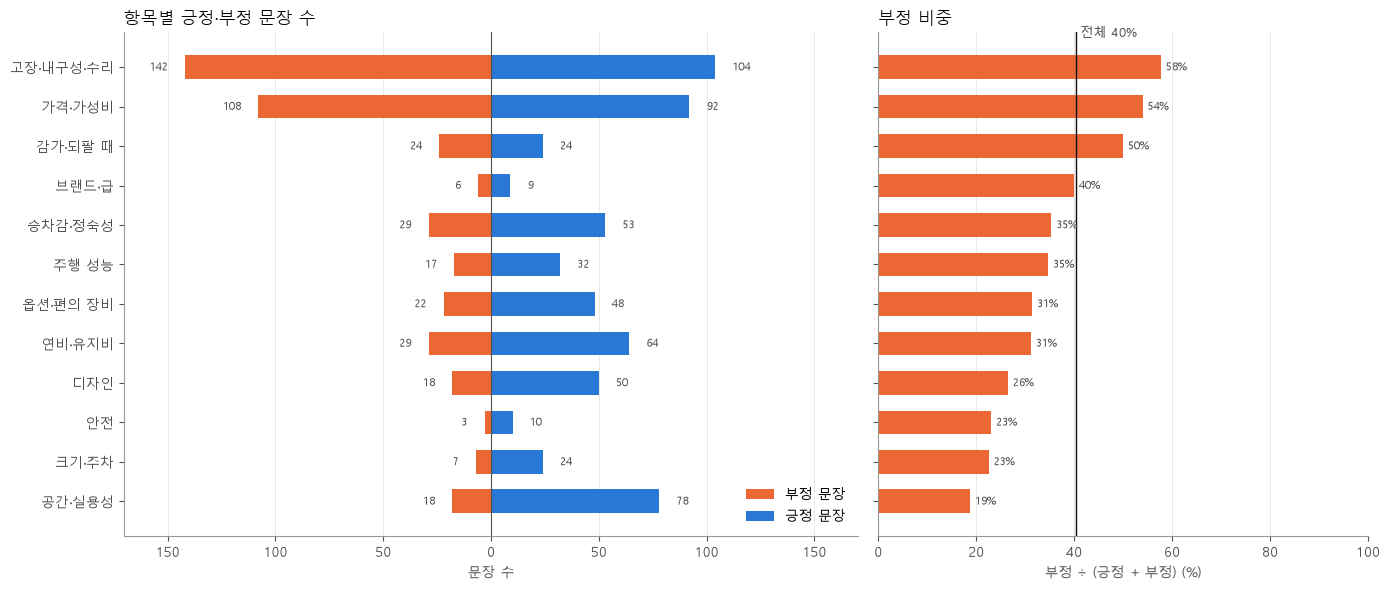

,본문에 나온 글,댓글에 나온 글,긍정 문장,중립·불확실 문장,부정 문장,댓글 문장,부정 비중
가격·가성비,48%,40%,92,"1,172",108,"1,372",54%
고장·내구성·수리,26%,32%,104,937,142,"1,183",58%
옵션·편의 장비,23%,19%,48,561,22,631,31%
연비·유지비,15%,18%,64,463,29,556,31%
공간·실용성,10%,13%,78,280,18,376,19%
승차감·정숙성,7%,12%,53,250,29,332,35%
감가·되팔 때,4%,10%,24,185,24,233,50%
디자인,7%,9%,50,190,18,258,26%
브랜드·급,7%,9%,9,168,6,183,40%
주행 성능,6%,8%,32,143,17,192,35%


In [36]:
order = aspect.sort_values("부정 비중").index
y = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
ax.barh(y, -aspect.loc[order, "부정 문장"], color=ORANGE, height=0.6, label="부정 문장")
ax.barh(y, aspect.loc[order, "긍정 문장"], color=BLUE, height=0.6, label="긍정 문장")
for i, a in enumerate(order):
    ax.text(-aspect.loc[a, "부정 문장"] - 8, i, f"{aspect.loc[a, '부정 문장']:,}", va="center", ha="right", fontsize=8, color="#52514e")
    ax.text(aspect.loc[a, "긍정 문장"] + 8, i, f"{aspect.loc[a, '긍정 문장']:,}", va="center", ha="left", fontsize=8, color="#52514e")
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_yticks(y, order)
limit = max(aspect["부정 문장"].max(), aspect["긍정 문장"].max()) * 1.2
ax.set_xlim(-limit, limit)
ax.xaxis.set_major_formatter(lambda v, _: f"{abs(v):,.0f}")
ax.set_xlabel("문장 수")
ax.set_title("항목별 긍정·부정 문장 수", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(y, aspect.loc[order, "부정 비중"] * 100, color=ORANGE, height=0.6)
ax.axvline(overall * 100, color=INK, linewidth=1)
ax.text(overall * 100, len(order) - 0.3, f" 전체 {overall:.0%}", fontsize=9, color="#52514e", va="bottom")
for i, a in enumerate(order):
    ax.text(aspect.loc[a, "부정 비중"] * 100 + 1, i, f"{aspect.loc[a, '부정 비중']:.0%}", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 100)
ax.set_xlabel("부정 ÷ (긍정 + 부정) (%)")
ax.set_title("부정 비중", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

aspect.style.format("{:.0%}", subset=["본문에 나온 글", "댓글에 나온 글", "부정 비중"]).format(
    "{:,}", subset=["긍정 문장", "중립·불확실 문장", "부정 문장", "댓글 문장"])

- **부정으로 더 많이 이야기되는 항목**: 고장·내구성·수리, 가격·가성비, 감가다. 자주 이야기되면서 부정 비중도 전체보다 높다. 사는 사람의 걱정거리다.
- **긍정으로 더 많이 이야기되는 항목**: 공간·실용성, 크기·주차, 디자인, 연비·유지비, 옵션이다. 차를 고르는 이유로 이야기된다.
- 브랜드·급과 안전은 긍정·부정 문장을 합쳐 20개가 안 되어 비중을 읽지 않는다.
- 항목이 나온 문장의 대부분은 "중립·불확실"이다. 긍정·부정 문장 수는 항목마다 수십~백여 개여서 비중은 대략적인 크기로만 읽는다.

항목마다 실제로 어떤 말이 오가는지 긍정·부정 문장을 몇 개씩 읽는다.

In [37]:
for a in aspect.index[:6]:
    hit = readable.index.intersection(opinions.index[opinions["aspects"].map(lambda v: a in v)])
    rows = opinions.loc[hit]
    print(f"[{a}]")
    for label in ["긍정", "부정"]:
        picked = rows.loc[rows["label"] == label, "text"]
        for text in picked.sample(min(4, len(picked)), random_state=2):
            print(f"  {label} | {text}")
    print()

[가격·가성비]
  긍정 | 사설 정비망도 잘되있고 정비 사례도 많고 정비 난이도도 높지 않아서 수리비가 저렴한 편입니다 +_+
  긍정 | QM6 싸고 좋은 차 맞습니다.
  긍정 | 중고차가격도 싸고 잘고르시면 고장도 없는편임.
  긍정 | 제가 아는 차중에 차도 싸고 연비도 좋은 최상의 차가 아반떼 1.6 lpi에요
  부정 | 어차피 중고싸게사서 고쳐가며 타다가 폐차하나 신차 무상서비스 받으면서 타다가 돈받고 중고로 파는거나..
  부정 | 부품수급도 더럽고 쉐보레보다 부품비용이 저렴하다뿐이지 현기 부품팔이 24년 전 절대 다음차량구매 하려면 현기차 안삽니다
  부정 | 500만원 미만 제네시스 BH 구입했다고 정비비용이 500만원짜리 아닙니다.
  부정 | 내부가 딱 가격 수준!!

[고장·내구성·수리]
  긍정 | 쏘나타에서 쓰는 2.0 누우에 6단 토컨 오토 조합이라 큰 잔고장이나 특장점이 없이 무난하게 탈 수 있죠
  긍정 | 경차들보다 내구성도 튼튼하니까요.
  긍정 | 수리 빠르고, 수리비 싸고, 에어컨 필터, 오일가격도 괜찮고..
  긍정 | 부품도 별로 안비싸요
  부정 | 하자투성이에 안되는것도 많고 욕을 한바가지를 ..
  부정 | 디젤은 별로고 크루즈 ㅠ 에혀 진짜 잔고장 많고 수리비 비싸요.
  부정 | 300~400짜리사서 수리비 써가며 타다가 폐차하나 적당한거 깔끔한거 타다가 감가 300~400 되고 중고로 방출하나..
  부정 | 누유 보이는 3.3 중고구매추천, 성능지 누유없음 체킹되어있는 매물로.

[옵션·편의 장비]
  긍정 | 올뉴소렌토 타다 G70 2.0텁 풀옵 중고로 작년에 기변했는데 혼자나 둘이 타기에 최고입니다.
  긍정 | 레이랑 비교하면 옵션, 배터리, 출력 모든게 좋음
  긍정 | 조용하고 풀옵이라 아주 편하게 운전합니다
  긍정 | 소나타옵션타협 신차
  부정 | 아뇨 케이카에서 보고왔는데 옵션 하나도없는 개깡통등급인데요
  부정 | 막탄것도 있고 관리 안된것도 있고 겉에만 수리해서 안은 썩은것도 있고 옵

## 10. 에이전트가 물어야 할 것

차를 추천받으려는 사람에게 무엇을 물어야 하는지를 댓글에서 찾는다.
차를 아는 사람들이 추천하기 전에 끌어오는 조건이 곧 물어야 할 질문 후보이고, 글쓴이가 본문에 이미 자주 적는 정보는 굳이 물을 필요가 없다.
3~5절의 조건 사전과 언급률을 쓴다.

### 10.1 질문 후보: 본문에 없는데 댓글이 꺼낸 조건

핵심 지표는 **본문에 그 조건이 없는 글 중 댓글이 그 조건을 꺼낸 비율**이다.
- 이 비율이 높다 → 글쓴이가 빠뜨려도 추천하는 사람이 끌어온다 → 에이전트가 먼저 물어야 할 후보
- 본문 언급률이 높다 → 사용자가 알아서 말한다 → 묻기보다 대화에서 뽑으면 된다

In [38]:
summary = []
for k in TOPICS:
    in_body = buy["body_topics"].map(lambda t: k in t)
    in_cmt = buy["comment_topics"].map(lambda t: k in t)
    summary.append({
        "주제": k,
        "본문 언급률": in_body.mean(),
        "댓글 언급률": in_cmt.mean(),
        "본문에 없을 때 댓글이 꺼낸 비율": in_cmt[~in_body].mean() if (~in_body).any() else 0,
    })
summary = pd.DataFrame(summary).set_index("주제").sort_values("본문에 없을 때 댓글이 꺼낸 비율", ascending=False)
summary.style.format("{:.1%}").bar(subset=["본문에 없을 때 댓글이 꺼낸 비율"], color="#f6b89c")

,본문 언급률,댓글 언급률,본문에 없을 때 댓글이 꺼낸 비율
주제,,,
신차/중고,64.0%,37.3%,22.9%
선호: 공간·옵션·안전,27.0%,24.4%,19.0%
선호: 연비·유지비,15.1%,21.5%,17.0%
예산,41.1%,24.6%,16.5%
연료·충전,34.4%,28.4%,15.7%
주차·차 크기,12.7%,16.8%,14.1%
선호: 성능·승차감,11.7%,15.1%,12.9%
선호: 디자인·브랜드,10.6%,11.4%,10.2%
현재 차량,12.2%,11.6%,9.7%


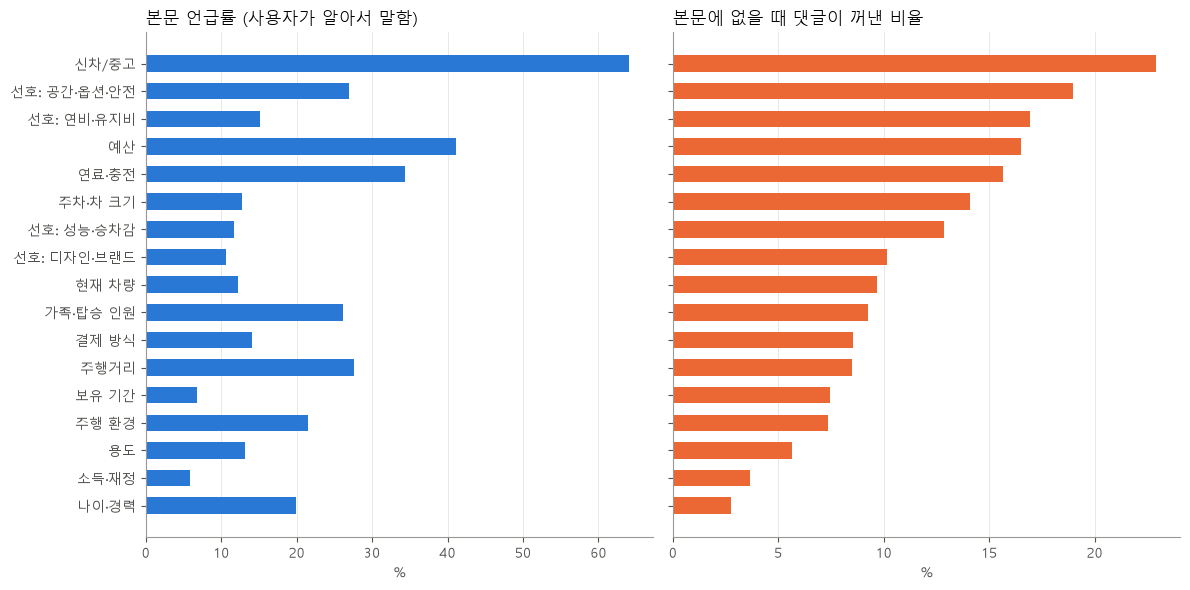

In [39]:
order = summary.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axes[0].barh(order, summary.loc[order, "본문 언급률"] * 100, color=BLUE, height=0.6)
axes[0].set_title("본문 언급률 (사용자가 알아서 말함)", loc="left")
axes[1].barh(order, summary.loc[order, "본문에 없을 때 댓글이 꺼낸 비율"] * 100, color=ORANGE, height=0.6)
axes[1].set_title("본문에 없을 때 댓글이 꺼낸 비율", loc="left")
for ax in axes:
    ax.set_xlabel("%")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 10.2 댓글의 되묻기

글쓴이 상황을 직접 묻는 댓글 문장만 따로 본다.
- 질문 문장: `?`로 끝나거나 `나요/까요/가요/니까/는지요`로 끝남
- 되묻기: 그중 `~시나요`, `~실 건가요`, `얼마나`, `몇 년`, `예산이` 같은 상황 질문 표현이 있고,
  `~않을까요`, `~어떠세요`, `굳이`처럼 제안·반어 표현이 없는 문장

보배드림 댓글은 묻기보다 바로 의견을 다는 경우가 대부분이라 되묻기는 적다. 빈도보다 실제 문장을 읽는 용도로 쓴다.

In [40]:
Q_END = re.compile(r"(\?|나요|까요|가요|니까|는지요|냐)\s*[.~!ㅠㅜㅎㅋ]*$")
ASK = re.compile(r"시나요|십니까|신가요|실\s?(?:건가요|거|예정|생각)|하시|타시|있으세요|있으신|되시|되나요|되세요|얼마나|"
                 r"몇\s?(?:년|명|km|키로|살|인|대|만)|언제|어떤\s?용도|무슨\s?용도|예산|애\s?있|아이\s?있")
SUGGEST = re.compile(r"않을까요|않나요|않습니까|아닌가요|아닐까요|아님\?|낫지|낫나요|나을까요|어떨까요|어떻습니까|어떠세요|"
                     r"어떠신|어때요|어떤가요|좋을듯|ㅋㅋ|굳이|왜")

def question_sentences(text):
    parts = re.split(r"(?<=[?.!])\s+|\n", text or "")
    return [p.strip() for p in parts if p.strip() and Q_END.search(p.strip())]

rows = [{"post_id": p["id"], "question": q, "topics": topics_in(q)}
        for _, p in buy.iterrows() for c in p["comments"] if not c["is_op"]
        for q in question_sentences(c["text"])]
questions = pd.DataFrame(rows)
asks = questions[questions["question"].str.contains(ASK) & ~questions["question"].str.contains(SUGGEST)]
print(f"질문 문장 {len(questions):,}개 → 되묻기로 추린 문장 {len(asks):,}개 (글 {asks['post_id'].nunique():,}건)")
print()
print(asks["question"].sample(30, random_state=3).to_string(index=False))

질문 문장 1,237개 → 되묻기로 추린 문장 76개 (글 74건)

                                                                           예산은요?
                                                 몇살이나 처 먹었는지 모르겠다만 그게 부탁하는 태도인가?
                                                     견적받고 불안해서 보배 가입하시고 글 올리셨습니까
                                             애매하면 차라리 아반떼 CN7 신형 신차 저리할부를 하시던가요.
                                                               출퇴근 거리가 얼마나 되시나요?
                                                              지출 가능한 돈이 얼마나 있어요?
                                                                 모하비 타시면 후회할텐데요?
                                                                     스타리아는 안되나요?
                                                             운동기구 평소에 자주 사용하시나요?
                            리스도 운용리스, 금융리스 이렇게 나뉘어 지는데 그거 다 설명하면 저 분이 이해하시겠습니까..
                                                                 근데 연봉이 어떻게 되시남?
아이고 추후에 아이가 크고 기변하실때 기변을 하시게되면 그로인한 감가로 금전적인 피해는 당연히 있으실텐데 그걸 고려하셨어도 아

In [41]:
(asks.explode("topics").dropna().groupby("topics")["post_id"].nunique()
     .sort_values(ascending=False).rename("되묻기가 나온 글 수").to_frame())

,되묻기가 나온 글 수
topics,
예산,12
신차/중고,7
연료·충전,4
결제 방식,3
가족·탑승 인원,3
주행 환경,3
선호: 연비·유지비,3
주행거리,2
주차·차 크기,2


### 10.3 글쓴이가 댓글로 덧붙이는 정보

댓글에 답하면서 글쓴이가 추가로 밝히는 조건. 본문에서 빠뜨리기 쉬운 정보다.

In [42]:
op = [{"post_id": p["id"], "topics": topics_in(c["text"])}
      for _, p in buy.iterrows() for c in p["comments"] if c["is_op"]]
op = pd.DataFrame(op)
print(f"글쓴이 댓글 {len(op):,}개, 글쓴이가 댓글을 단 글 {op['post_id'].nunique():,}건")
(op.explode("topics").dropna().groupby("topics")["post_id"].nunique()
   .sort_values(ascending=False).rename("글쓴이가 댓글에서 밝힌 글 수").to_frame())

글쓴이 댓글 3,416개, 글쓴이가 댓글을 단 글 1,006건


,글쓴이가 댓글에서 밝힌 글 수
topics,
신차/중고,160
연료·충전,130
예산,128
선호: 공간·옵션·안전,102
가족·탑승 인원,94
선호: 연비·유지비,82
주차·차 크기,73
선호: 디자인·브랜드,64
주행거리,57


### 10.4 agent-design.md 질문 항목과 비교

| agent-design 항목 | 대응 주제 |
|---|---|
| 예산 | 예산 |
| 소득·월 여유 | 소득·재정 |
| 용도 | 용도, 주행 환경 |
| 탑승 인원 | 가족·탑승 인원 |
| 보유 기간 | 보유 기간 |
| 주행거리·가격·연식 (선택값) | 주행거리, 예산, 신차/중고 |

In [43]:
design = {"예산": ["예산"], "소득·월 여유": ["소득·재정"], "용도": ["용도", "주행 환경"],
          "탑승 인원": ["가족·탑승 인원"], "보유 기간": ["보유 기간"]}
in_design = {t for ts in design.values() for t in ts}
view = summary.copy()
view["agent-design에 있음"] = ["O" if k in in_design else "" for k in view.index]
view.style.format("{:.1%}", subset=["본문 언급률", "댓글 언급률", "본문에 없을 때 댓글이 꺼낸 비율"])

,본문 언급률,댓글 언급률,본문에 없을 때 댓글이 꺼낸 비율,agent-design에 있음
주제,,,,
신차/중고,64.0%,37.3%,22.9%,
선호: 공간·옵션·안전,27.0%,24.4%,19.0%,
선호: 연비·유지비,15.1%,21.5%,17.0%,
예산,41.1%,24.6%,16.5%,O
연료·충전,34.4%,28.4%,15.7%,
주차·차 크기,12.7%,16.8%,14.1%,
선호: 성능·승차감,11.7%,15.1%,12.9%,
선호: 디자인·브랜드,10.6%,11.4%,10.2%,
현재 차량,12.2%,11.6%,9.7%,


## 11. 정리

수치는 일부 데이터 기준이고, 분류가 정규식과 가벼운 모델이라 대략적인 크기로 읽는다.

**데이터**
- 리뷰 데이터는 지금 보배드림 하나다. 글 3,105건과 댓글 24,407개가 있고, 수입차 게시판 글은 아직 없다.
- 검색어에 걸린 글 가운데 차를 고르는 글은 절반 정도(1,626건)다. 나머지는 용품·정비·분쟁 글과 차와 관계없는 글이다.
- 본문이 없는 글이 55건, 댓글이 없는 글이 89건이다. 댓글이 100개를 넘는 글은 댓글 일부만 수집됐다(2건).

**감정 분류**
- 가벼운 공개 모델 일곱 개를 시험했는데 커뮤니티 댓글에는 잘 맞지 않았다. 댓글 문장의 절반이 평가가 아닌 사실 전달·질문·조언이기 때문이다.
- 그중 가장 나은 모델(KoELECTRA-base)에서 확률이 크게 쏠린 문장만 썼다. 문장의 8%가 긍정, 5%가 부정으로 잡혔다.
- 읽어서 확인한 표본에서 부정 판정은 15개 중 12개, 긍정 판정은 15개 중 7~10개가 맞았다. 경향을 보는 데는 쓸 수 있고, 문장 하나의 판정으로 쓰기에는 부족하다.

**긍정·부정 키워드**
- 긍정 문장에는 만족·최고 같은 평가어와 공간·실내·트렁크·가성비·하이브리드, 모델 이름이 많다.
- 부정 문장에는 환불·딜러·이력·보증 같은 거래 관련 말과 수리·수리비·교환·비용 같은 수리 비용 관련 말이 많다.

**차를 살 때 무엇을 중점으로 보나**
- 가장 많이 이야기되는 것은 가격·가성비이고, 그다음이 고장·내구성·수리, 옵션, 연비·유지비다.
- 글쓴이보다 댓글이 더 자주 꺼내는 것은 고장·수리와 감가다. 조언하는 사람은 사고 난 뒤의 비용을 본다.
- 고장·수리, 가격, 감가는 부정으로 이야기되는 비중이 높고, 공간·디자인·연비·옵션은 긍정으로 이야기되는 비중이 높다.
- 정리하면, 걱정하는 것은 "얼마에 사서, 고장 없이, 손해 덜 보고 탈 수 있나"이고, 고르는 이유로 드는 것은 공간·연비·옵션·디자인이다.

**에이전트가 물어야 할 것 (10절)**
1. 사용자가 알아서 말하는 것: 신차/중고(64%), 예산(41%), 연료(34%), 주행거리(28%), 공간·옵션·안전(27%), 가족·탑승 인원(26%).
   이 항목들은 먼저 묻기보다 첫 메시지에서 뽑아내고, 빠졌을 때만 물으면 된다.
2. 댓글이 본문보다 자주 꺼내는 것: 연비·유지비, 주차·차 크기, 성능·승차감.
   사용자는 잘 안 쓰는데 추천하는 사람은 판단 근거로 쓰는 조건이다. agent-design.md의 "모델 수준 니즈"에 해당한다.
3. 소득·재정과 보유 기간은 본문에도 댓글에도 드물다(본문 6~7%).
   agent-design.md는 둘 다 묻도록 되어 있다. 커뮤니티에서는 거의 다루지 않는 축이라, 묻는다면 왜 묻는지 설명이 필요하다.
4. 직접 되묻는 댓글은 적다(구매 고민 글의 약 5%). 그중에서는 예산을 묻는 경우가 가장 많다.

## 12. 한계

- 지금 있는 리뷰 데이터는 보배드림 하나다. 보배드림 이용자(30~50대 남성 비중이 높은 자동차 커뮤니티)의 시각이라, 첫 차를 사는 사람이 실제로 궁금해하는 것과는 다를 수 있다.
- 수집이 끝나지 않아 수입차 게시판 글이 없다.
- 감정 분류 모델은 리뷰 문장으로 학습한 것이라 커뮤니티 댓글에 잘 맞지 않는다. 확률이 크게 쏠린 문장만 썼기 때문에 긍정·부정으로 잡힌 문장은 전체의 일부이고, 반어·비꼼은 잘못 판정된다.
- 감정은 문장의 감정이지 특정 차나 항목에 대한 평가가 아니다. "A는 좋은데 B는 별로"처럼 한 문장에 둘이 섞이면 구분하지 못한다.
- 구매 고민 글 판별, 조건·항목 분류가 모두 정규식이라 오분류가 있다. 표본으로 확인한 정도의 정확도로 읽어야 한다.
- "댓글이 꺼낸 비율"은 댓글이 그 조건을 언급했다는 뜻이지 꼭 질문했다는 뜻은 아니다. 되묻기 판별(10.2절)도 문장 표현만 본다.
- 댓글이 100개를 넘는 글은 글 화면에 처음 보이는 댓글 한 쪽만 수집했다(1.4절).
- 정확도를 높이려면 LLM으로 문장마다 "어떤 차의 어떤 항목을 어떻게 평가했는지"를 뽑는 단계를 추가하면 된다.